In [ ]:
# pip install -U langgraph
from typing import TypedDict
from langgraph.graph import StateGraph, START, END


# 1. STATE: the shared memory every node reads from and writes to
class State(TypedDict):
    topic: str
    draft: str
    attempts: int
    approved: bool


# 2. NODES: plain functions. Take state in, return ONLY the fields you changed
def write(state: State) -> dict:
    attempts = state["attempts"] + 1
    draft = f"Draft v{attempts} about {state['topic']}" + " (more detail)" * attempts
    print(f"write  -> attempt {attempts}, {len(draft)} chars")
    return {"draft": draft, "attempts": attempts}


def review(state: State) -> dict:
    approved = len(state["draft"]) > 50  # fake "quality check"
    print(f"review -> approved={approved}")
    return {"approved": approved}


# 3. ROUTER: decides which edge to follow next (this is the "conditional edge")
def route(state: State) -> str:
    if state["approved"] or state["attempts"] >= 5:  # hard stop prevents infinite loops
        return "done"
    return "retry"


# 4. BUILD THE GRAPH
builder = StateGraph(State)
builder.add_node("write", write)
builder.add_node("review", review)

builder.add_edge(START, "write")          # fixed edge
builder.add_edge("write", "review")       # fixed edge
builder.add_conditional_edges(            # decision point
    "review", route, {"retry": "write", "done": END}
)

graph = builder.compile()                 # validates + turns it into a runnable

# 5. RUN
result = graph.invoke(
    {"topic": "LangGraph", "draft": "", "attempts": 0, "approved": False}
)
print(result)

write  -> attempt 1, 38 chars
review -> approved=False
write  -> attempt 2, 52 chars
review -> approved=True
{'topic': 'LangGraph', 'draft': 'Draft v2 about LangGraph (more detail) (more detail)', 'attempts': 2, 'approved': True}


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 2.1 MB/s eta 0:00:00
Enter your Groq API key: ··········
Models available to you:
  - canopylabs/orpheus-arabic-saudi
  - openai/gpt-oss-safeguard-20b
  - openai/gpt-oss-120b
  - meta-llama/llama-prompt-guard-2-22m
  - whisper-large-v3-turbo
  - qwen/qwen3.8-27b
  - openai/gpt-oss-20b
  - whisper-large-v3
  - allam-2-7b
  - meta-llama/llama-prompt-guard-2-86m
  - canopylabs/orpheus-v1-english

Using model: openai/gpt-oss-120b
Hello!


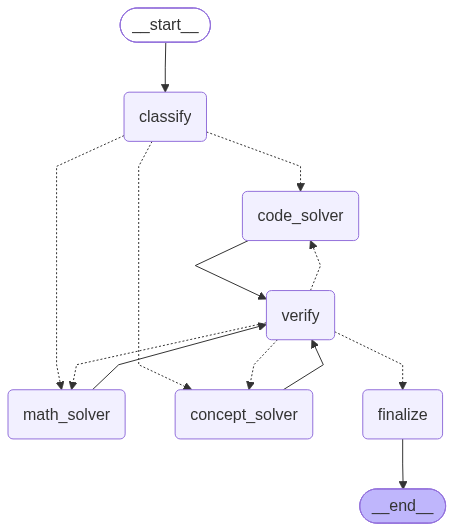

Workflow trace:
  ➡ classify -> category = math
  ➡ math_solver
  ➡ verify -> verdict = PASS
  ➡ finalize

Category : MATH
Attempts : 1   |   Verified: PASS

--- Reasoning ---
****  
1. Compute the original speed: \( \text{speed} = \frac{240\text{ km}}{4\text{ h}} = 60\text{ km/h}\).  
2. Increase the speed by 20 km/h: \(60\text{ km/h} + 20\text{ km/h} = 80\text{ km/h}\).  
3. Find the time needed to travel 360 km at the new speed:  
   \[
   \text{time} = \frac{360\text{ km}}{80\text{ km/h}} = 4.5\text{ h}.
   \]  
4. Convert 0.5 h to minutes: \(0.5 \times 60 = 30\) minutes.  

**

--- Answer ---
**  
It will take **4 hours 30 minutes** to cover 360 km at the increased speed.
Workflow trace:
  ➡ classify -> category = concept
  ➡ concept_solver
  ➡ verify -> verdict = PASS
  ➡ finalize

Category : CONCEPT
Attempts : 1   |   Verified: PASS

--- Reasoning ---
1. A **process** is an independent program in execution, with its own memory space, resources (files, handles), and at least one 

In [ ]:
# -*- coding: utf-8 -*-
"""Cot Langgraph LLM.ipynb

Automatically generated by Colab.

Original file is located at
    https://colab.research.google.com/drive/1AcSTbjWE3A35cJUmFuOTT3dOd_sLFzvs
"""

!pip install -q langgraph langchain-groq langchain-core

import os, re, getpass
from typing import TypedDict, Literal
from groq import Groq
from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage, HumanMessage

# Option 1: your Colab secret (your secret is named "Project"). Falls back to typing the key.
try:
    from google.colab import userdata
    key = userdata.get("Project").strip()
except Exception:
    key = getpass.getpass("Enter your Groq API key: ").strip()
os.environ["GROQ_API_KEY"] = key

# Ask Groq which models this key can actually use
available = [m.id for m in Groq().models.list().data]
print("Models available to you:")
for m in available:
    print("  -", m)

# Pick the first preferred chat model that exists (skips whisper/tts/guard models)
preferred = ["llama-3.3-70b-versatile", "openai/gpt-oss-120b",
             "llama-3.1-8b-instant", "openai/gpt-oss-20b"]
MODEL = next((m for m in preferred if m in available), None)
if MODEL is None:
    MODEL = next(m for m in available
                 if not any(x in m.lower() for x in ["whisper", "tts", "guard", "prompt-guard", "embed"]))
print("\nUsing model:", MODEL)

llm = ChatGroq(model=MODEL, temperature=0)

def ask(system_prompt: str, user_prompt: str) -> str:
    resp = llm.invoke([SystemMessage(content=system_prompt), HumanMessage(content=user_prompt)])
    return resp.content.strip()

# Quick test
print(ask("You are a helpful assistant.", "Say hello in one short sentence."))

class AgentState(TypedDict):
    question: str    # user's question
    category: str    # math | concept | code
    reasoning: str   # chain-of-thought steps from the solver
    answer: str      # final answer from the solver
    verdict: str     # PASS | FAIL from the verifier
    feedback: str    # verifier's comments, fed back to the solver on retry
    attempts: int    # how many times a solver has run
    final: str       # formatted output shown to the user

MAX_ATTEMPTS = 2

CLASSIFY_PROMPT = """You are a question classifier for a student doubt-solving app.
Think step by step:
1. Identify what the student is actually asking.
2. Look for clues: numbers/equations/calculations -> math; "explain/what is/why/difference" -> concept; code/programming/bug/syntax -> code.
3. Decide the single best category.
Write your steps briefly, then end with exactly one last line:
CATEGORY: math   (or concept, or code)"""

SOLVER_BASE = """You are an expert tutor. {style}
Use chain-of-thought: think step by step and write each step as a numbered line.
Format your reply EXACTLY like this:
REASONING:
1. ...
2. ...
FINAL ANSWER:
<clear, concise answer for a college student>"""

STYLES = {
    "math": "You solve math, aptitude and numerical problems. Show every calculation and double-check arithmetic.",
    "concept": "You explain theory and concepts simply, with a short real-world example or analogy.",
    "code": "You solve programming questions. Explain the logic first, then give correct, runnable code in a code block.",
}

VERIFY_PROMPT = """You are a strict reviewer checking a tutor's work.
Think step by step: re-read the question, check each numbered reasoning step for errors,
then check whether the final answer follows from the steps and truly answers the question.
Write 2-4 short lines of feedback, then end with exactly one last line:
VERDICT: PASS   (or VERDICT: FAIL)"""

def classify_node(state: AgentState):
    text = ask(CLASSIFY_PROMPT, state["question"])
    m = re.search(r"CATEGORY:\s*(math|concept|code)", text, re.I)
    category = m.group(1).lower() if m else "concept"   # safe default
    return {"category": category, "attempts": 0, "feedback": ""}

def make_solver(category: str):
    """Factory: builds one solver node per category, each with its own CoT prompt."""
    def solver_node(state: AgentState):
        user = f"Question: {state['question']}"
        if state["feedback"]:
            user += f"\n\nA reviewer found problems with your previous attempt:\n{state['feedback']}\nFix them."
        text = ask(SOLVER_BASE.format(style=STYLES[category]), user)
        reasoning, _, answer = text.partition("FINAL ANSWER:")
        return {
            "reasoning": reasoning.replace("REASONING:", "").strip(),
            "answer": answer.strip() or text,
            "attempts": state["attempts"] + 1,
        }
    return solver_node

math_solver = make_solver("math")
concept_solver = make_solver("concept")
code_solver = make_solver("code")

def verify_node(state: AgentState):
    user = (f"Question: {state['question']}\n\nTutor's reasoning:\n{state['reasoning']}\n\n"
            f"Tutor's final answer:\n{state['answer']}")
    text = ask(VERIFY_PROMPT, user)
    m = re.search(r"VERDICT:\s*(PASS|FAIL)", text, re.I)
    verdict = m.group(1).upper() if m else "PASS"
    feedback = re.sub(r"VERDICT:.*", "", text, flags=re.I | re.S).strip()
    return {"verdict": verdict, "feedback": feedback}

def finalize_node(state: AgentState):
    note = ""
    if state["verdict"] == "FAIL":
        note = "\n\n(Note: the self-check still had doubts after the maximum retries, so please double-check this answer.)"
    final = (f"Category : {state['category'].upper()}\n"
             f"Attempts : {state['attempts']}   |   Verified: {state['verdict']}\n\n"
             f"--- Reasoning ---\n{state['reasoning']}\n\n"
             f"--- Answer ---\n{state['answer']}{note}")
    return {"final": final}

def route_after_classify(state: AgentState) -> str:
    """Decide which solver node runs next, based on the category in the state."""
    return f"{state['category']}_solver"

def route_after_verify(state: AgentState) -> str:
    """Pass, or out of retries -> finalize. Otherwise loop back to the same solver."""
    if state["verdict"] == "PASS" or state["attempts"] >= MAX_ATTEMPTS:
        return "finalize"
    return f"{state['category']}_solver"

from langgraph.graph import StateGraph, START, END

builder = StateGraph(AgentState)

builder.add_node("classify", classify_node)
builder.add_node("math_solver", math_solver)
builder.add_node("concept_solver", concept_solver)
builder.add_node("code_solver", code_solver)
builder.add_node("verify", verify_node)
builder.add_node("finalize", finalize_node)

builder.add_edge(START, "classify")
builder.add_conditional_edges("classify", route_after_classify,
                              ["math_solver", "concept_solver", "code_solver"])
for s in ["math_solver", "concept_solver", "code_solver"]:
    builder.add_edge(s, "verify")
builder.add_conditional_edges("verify", route_after_verify,
                              ["math_solver", "concept_solver", "code_solver", "finalize"])
builder.add_edge("finalize", END)

app = builder.compile()

# Draw the graph (great for your report and viva)
from IPython.display import Image, display
try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception:
    print(app.get_graph().draw_mermaid())   # paste this at mermaid.live to see the diagram

def ask_app(question: str):
    state = {"question": question, "category": "", "reasoning": "", "answer": "",
             "verdict": "", "feedback": "", "attempts": 0, "final": ""}
    print("Workflow trace:")
    for step in app.stream(state, stream_mode="updates"):
        for node, update in step.items():
            extra = ""
            if node == "classify": extra = f" -> category = {update['category']}"
            if node == "verify":   extra = f" -> verdict = {update['verdict']}"
            print(f"  ➡ {node}{extra}")
            state.update(update)
    print("\n" + "=" * 60)
    print(state["final"])

ask_app("A train travels 240 km in 4 hours. If it speeds up by 20 km/h, how long will it take to cover 360 km?")

ask_app("What is the difference between a process and a thread?")
ask_app("Write a Python function to check whether a string is a palindrome.")

Using model: openai/gpt-oss-120b
LLM 1 and LLM 2 are ready!


LANGGRAPH CREATED SUCCESSFULLY

Generating LangGraph visualization...



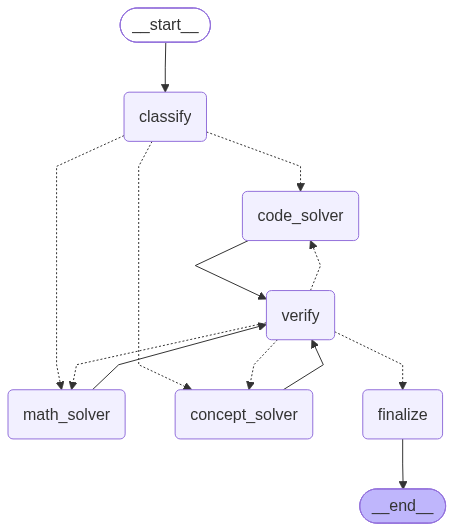


Graph visualization displayed successfully.


              SYSTEM READY

LLM 1 will generate an answer.
LLM 2 will evaluate that answer using LangGraph.

Example questions:

1. What is 25% of 200?
2. What is the difference between a process and a thread?
3. Write Python code to check whether a number is prime.


Enter your question: What is 25% of 200?


                 LLM 1

LLM 1 is generating the original answer...

LLM 1 ANSWER:
------------------------------------------------------------
25% of 200 is **50**.

**Explanation:** 25% means 25 per 100, or 0.25 as a decimal. Multiply 0.25 by 200:

\(0.25 \times 200 = 50\).


                 LLM 2

Starting LangGraph evaluation...


➡ CLASSIFY NODE
Category: MATH
  ➡ classify

➡ MATH SOLVER
  ➡ math_solver

➡ VERIFY NODE
Verdict: PASS
  ➡ verify

➡ FINALIZE NODE
  ➡ finalize


                 FINAL EVALUATION

Category : MATH
Attempts : 1
Verified : PASS

------------------------------------------------------------
QUESTION
------

In [ ]:
# ============================================================
# TWO-LLM LANGGRAPH ANSWER EVALUATOR
# LLM 1 = Generates the original answer
# LLM 2 = LangGraph evaluator
# ============================================================


# ============================================================
# 1. INSTALL
# ============================================================

!pip install -q -U langgraph langchain-groq


# ============================================================
# 2. IMPORTS
# ============================================================

import re
from typing import TypedDict

from google.colab import userdata
from langchain_groq import ChatGroq

from langgraph.graph import StateGraph, START, END

from IPython.display import Image, display


# ============================================================
# 3. GET GROQ API KEY
# ============================================================

GROQ_API_KEY = userdata.get("GROK_API_KEY")

if not GROQ_API_KEY:
    raise ValueError(
        """
Groq API key not found.

In Google Colab:

1. Click the 🔑 Secrets icon
2. Add a new secret
3. Name it:

groq

4. Put your Groq API key as the value
5. Enable notebook access
"""
    )


# ============================================================
# 4. CREATE LLM
# ============================================================

MODEL = "openai/gpt-oss-120b"

llm = ChatGroq(
    model=MODEL,
    groq_api_key=GROQ_API_KEY,
    temperature=0
)

print("Using model:", MODEL)
print("LLM 1 and LLM 2 are ready!")


# ============================================================
# 5. LANGGRAPH STATE
# ============================================================

class AgentState(TypedDict):

    question: str

    # Answer generated by LLM 1
    llm1_answer: str

    # Category detected by LLM 2
    category: str

    # LLM 2 evaluation
    reasoning: str
    answer: str

    # Verification
    verdict: str
    feedback: str

    # Number of evaluation attempts
    attempts: int

    # Final output
    final: str


MAX_ATTEMPTS = 2


# ============================================================
# 6. LLM 1
# ============================================================
# LLM 1 creates the original answer.
# ============================================================

def generate_llm1_answer(question):

    print("\n")
    print("=" * 60)
    print("                 LLM 1")
    print("=" * 60)

    print("\nLLM 1 is generating the original answer...\n")

    prompt = f"""
You are LLM 1.

Answer the following question normally.

Question:
{question}

Give a clear answer with a short explanation.

Do not talk about this evaluation system.
"""

    response = llm.invoke(prompt)

    answer = response.content.strip()

    print("LLM 1 ANSWER:")
    print("-" * 60)
    print(answer)

    return answer


# ============================================================
# 7. CLASSIFICATION NODE
# ============================================================

def classify_node(state):

    print("\n➡ CLASSIFY NODE")

    prompt = f"""
You are LLM 2.

You are evaluating an answer produced by another LLM.

Classify the question into exactly ONE category.

Categories:

math
concept
code

Rules:

math:
Calculations, equations, percentages, speed,
distance, algebra, numerical problems.

concept:
Definitions, theories, explanations,
comparisons and general knowledge.

code:
Programming, debugging, programming syntax,
algorithms or requests for code.

Question:
{state["question"]}

Answer produced by LLM 1:
{state["llm1_answer"]}

Return ONLY:

CATEGORY: math

or

CATEGORY: concept

or

CATEGORY: code
"""

    response = llm.invoke(prompt)

    text = response.content.strip()

    match = re.search(
        r"CATEGORY\s*:\s*(math|concept|code)",
        text,
        re.IGNORECASE
    )

    if match:
        category = match.group(1).lower()
    else:
        category = "concept"

    print("Category:", category.upper())

    return {
        "category": category,
        "attempts": 0,
        "feedback": ""
    }


# ============================================================
# 8. MATH EVALUATOR
# ============================================================

def math_solver(state):

    print("\n➡ MATH SOLVER")

    prompt = f"""
You are LLM 2, an answer evaluator.

Evaluate the answer produced by LLM 1.

Question:
{state["question"]}

LLM 1 ANSWER:
{state["llm1_answer"]}

Previous verifier feedback:
{state["feedback"]}

Check the mathematical answer carefully.

Do the calculation yourself.

Do not blindly trust LLM 1.

Give:

ANALYSIS:
Briefly explain whether the calculation is correct.

CORRECT ANSWER:
Give the correct answer.

Keep the response concise.
"""

    response = llm.invoke(prompt)

    attempts = state["attempts"] + 1

    return {
        "reasoning": response.content.strip(),
        "answer": response.content.strip(),
        "attempts": attempts
    }


# ============================================================
# 9. CONCEPT EVALUATOR
# ============================================================

def concept_solver(state):

    print("\n➡ CONCEPT SOLVER")

    prompt = f"""
You are LLM 2, an answer evaluator.

Evaluate the answer produced by LLM 1.

Question:
{state["question"]}

LLM 1 ANSWER:
{state["llm1_answer"]}

Previous verifier feedback:
{state["feedback"]}

Check:

1. Factual correctness
2. Relevance
3. Completeness
4. Contradictions

Do not blindly trust LLM 1.

Give:

ANALYSIS:
Briefly explain whether the answer is correct.

CORRECT ANSWER:
Give a concise correct answer.

Keep the response concise.
"""

    response = llm.invoke(prompt)

    attempts = state["attempts"] + 1

    return {
        "reasoning": response.content.strip(),
        "answer": response.content.strip(),
        "attempts": attempts
    }


# ============================================================
# 10. CODE EVALUATOR
# ============================================================

def code_solver(state):

    print("\n➡ CODE SOLVER")

    prompt = f"""
You are LLM 2, a programming answer evaluator.

Evaluate the answer produced by LLM 1.

Question:
{state["question"]}

LLM 1 ANSWER:
{state["llm1_answer"]}

Previous verifier feedback:
{state["feedback"]}

Check:

1. Syntax
2. Logic
3. Correctness
4. Whether the code answers the question
5. Obvious errors

Do not blindly trust LLM 1.

Give:

ANALYSIS:
Briefly explain whether the answer/code is correct.

CORRECT ANSWER:
Give corrected code or answer if necessary.

Keep the response concise.
"""

    response = llm.invoke(prompt)

    attempts = state["attempts"] + 1

    return {
        "reasoning": response.content.strip(),
        "answer": response.content.strip(),
        "attempts": attempts
    }


# ============================================================
# 11. VERIFY NODE
# ============================================================

def verify_node(state):

    print("\n➡ VERIFY NODE")

    prompt = f"""
You are the final verifier.

Question:
{state["question"]}

ORIGINAL ANSWER FROM LLM 1:
{state["llm1_answer"]}

LLM 2 EVALUATION:
{state["answer"]}

Determine whether the ORIGINAL LLM 1 answer is correct.

Important:

PASS = LLM 1 answer is correct.

FAIL = LLM 1 answer is incorrect.

Do not mark PASS simply because LLM 2 produced an answer.

Return exactly:

VERDICT: PASS
FEEDBACK: The original answer is correct.

OR:

VERDICT: FAIL
FEEDBACK: Explain what is wrong with the original answer.
"""

    response = llm.invoke(prompt)

    text = response.content.strip()

    verdict_match = re.search(
        r"VERDICT\s*:\s*(PASS|FAIL)",
        text,
        re.IGNORECASE
    )

    if verdict_match:
        verdict = verdict_match.group(1).upper()
    else:
        verdict = "FAIL"

    feedback_match = re.search(
        r"FEEDBACK\s*:\s*(.*)",
        text,
        re.IGNORECASE | re.DOTALL
    )

    if feedback_match:
        feedback = feedback_match.group(1).strip()
    else:
        feedback = text

    print("Verdict:", verdict)

    return {
        "verdict": verdict,
        "feedback": feedback
    }


# ============================================================
# 12. FINALIZE NODE
# ============================================================

def finalize_node(state):

    print("\n➡ FINALIZE NODE")

    final_text = f"""

============================================================
                 FINAL EVALUATION
============================================================

Category : {state["category"].upper()}
Attempts : {state["attempts"]}
Verified : {state["verdict"]}

------------------------------------------------------------
QUESTION
------------------------------------------------------------

{state["question"]}

------------------------------------------------------------
ANSWER GENERATED BY LLM 1
------------------------------------------------------------

{state["llm1_answer"]}

------------------------------------------------------------
LLM 2 EVALUATION
------------------------------------------------------------

{state["answer"]}

------------------------------------------------------------
VERIFIER FEEDBACK
------------------------------------------------------------

{state["feedback"]}

============================================================
"""

    return {
        "final": final_text
    }


# ============================================================
# 13. ROUTING AFTER CLASSIFICATION
# ============================================================

def route_after_classify(state):

    if state["category"] == "math":
        return "math_solver"

    elif state["category"] == "code":
        return "code_solver"

    else:
        return "concept_solver"


# ============================================================
# 14. ROUTING AFTER VERIFICATION
# ============================================================

def route_after_verify(state):

    # Correct answer
    if state["verdict"] == "PASS":
        return "finalize"

    # Maximum attempts reached
    if state["attempts"] >= MAX_ATTEMPTS:
        return "finalize"

    # Retry appropriate evaluator
    if state["category"] == "math":
        return "math_solver"

    elif state["category"] == "code":
        return "code_solver"

    else:
        return "concept_solver"


# ============================================================
# 15. CREATE LANGGRAPH
# ============================================================

builder = StateGraph(AgentState)


# Add nodes

builder.add_node(
    "classify",
    classify_node
)

builder.add_node(
    "math_solver",
    math_solver
)

builder.add_node(
    "concept_solver",
    concept_solver
)

builder.add_node(
    "code_solver",
    code_solver
)

builder.add_node(
    "verify",
    verify_node
)

builder.add_node(
    "finalize",
    finalize_node
)


# ============================================================
# 16. GRAPH CONNECTIONS
# ============================================================

# START → CLASSIFY

builder.add_edge(
    START,
    "classify"
)


# CLASSIFY → appropriate evaluator

builder.add_conditional_edges(
    "classify",
    route_after_classify,
    [
        "math_solver",
        "concept_solver",
        "code_solver"
    ]
)


# Evaluators → VERIFY

builder.add_edge(
    "math_solver",
    "verify"
)

builder.add_edge(
    "concept_solver",
    "verify"
)

builder.add_edge(
    "code_solver",
    "verify"
)


# VERIFY → FINALIZE or RETRY

builder.add_conditional_edges(
    "verify",
    route_after_verify,
    [
        "math_solver",
        "concept_solver",
        "code_solver",
        "finalize"
    ]
)


# FINALIZE → END

builder.add_edge(
    "finalize",
    END
)


# Compile

app = builder.compile()


print("\n")
print("=" * 60)
print("LANGGRAPH CREATED SUCCESSFULLY")
print("=" * 60)


# ============================================================
# 17. DISPLAY GRAPH
# ============================================================
# This is ONLY for visualization.
# It is kept separate from the actual program.
# ============================================================

print("\nGenerating LangGraph visualization...\n")

try:

    graph_png = app.get_graph().draw_mermaid_png()

    display(Image(graph_png))

    print("\nGraph visualization displayed successfully.")

except Exception as e:

    print("\nGraph image could not be displayed.")
    print("\nMermaid graph:\n")

    print(
        app.get_graph().draw_mermaid()
    )


# ============================================================
# 18. MAIN SYSTEM
# ============================================================

def run_system(question):

    # --------------------------------------------------------
    # LLM 1
    # --------------------------------------------------------

    llm1_answer = generate_llm1_answer(
        question
    )


    # --------------------------------------------------------
    # Initial LangGraph state
    # --------------------------------------------------------

    state = {
        "question": question,

        "llm1_answer": llm1_answer,

        "category": "",

        "reasoning": "",

        "answer": "",

        "verdict": "",

        "feedback": "",

        "attempts": 0,

        "final": ""
    }


    # --------------------------------------------------------
    # LLM 2 / LANGGRAPH
    # --------------------------------------------------------

    print("\n")
    print("=" * 60)
    print("                 LLM 2")
    print("=" * 60)

    print("\nStarting LangGraph evaluation...\n")


    for step in app.stream(
        state,
        stream_mode="updates"
    ):

        for node, update in step.items():

            state.update(update)

            print(
                f"  ➡ {node}"
            )


    # --------------------------------------------------------
    # FINAL OUTPUT
    # --------------------------------------------------------

    print(
        state["final"]
    )


# ============================================================
# 19. USER INPUT
# ============================================================

print("\n")
print("=" * 60)
print("              SYSTEM READY")
print("=" * 60)

print(
    """
LLM 1 will generate an answer.
LLM 2 will evaluate that answer using LangGraph.

Example questions:

1. What is 25% of 200?
2. What is the difference between a process and a thread?
3. Write Python code to check whether a number is prime.
"""
)


question = input(
    "\nEnter your question: "
)


# ============================================================
# 20. RUN
# ============================================================

run_system(question)

             TWO DIFFERENT LLM SYSTEM

LLM 1: qwen/qwen3.8-27b
LLM 2: openai/gpt-oss-120b

Both LLMs are ready!


                 LANGGRAPH WORKFLOW


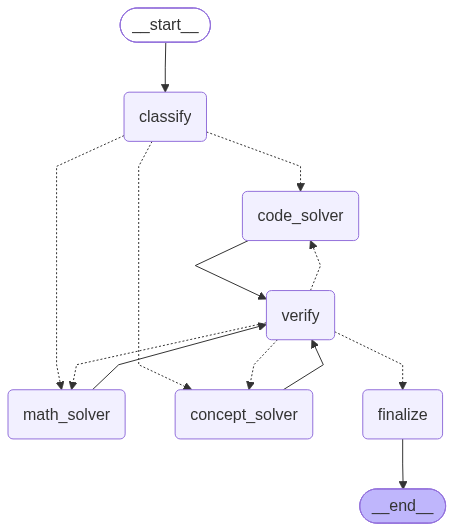




                 AUTOMATIC TESTING



#################################################################
TEST
#################################################################

Question:
What is 25% of 200?


                         LLM 1

Model: qwen/qwen3.8-27b

LLM 1 ANSWER:
-----------------------------------------------------------------
To find 25% of 200, you can convert the percentage to a decimal or fraction and multiply it by the number.

**Calculation:**
1.  Convert 25% to a decimal: $25\% = 0.25$
2.  Multiply by 200: $0.25 \times 200 = 50$

Alternatively, since 25% is equal to $\frac{1}{4}$:
$$ \frac{1}{4} \times 200 = 50 $$

**Answer:**
25% of 200 is **50**.


                         LLM 2

Model: openai/gpt-oss-120b

Workflow trace:

➡ CLASSIFY
Category: MATH
  ➡ classify -> category = math

➡ MATH EVALUATOR
  ➡ math_solver

➡ VERIFY
Verdict: PASS
  ➡ verify -> verdict = PASS

➡ FINALIZE
  ➡ finalize

                 FINAL EVALUATION

LLM 1 : qwen/qwen3.8-27b
LLM 2 :

In [ ]:
# ============================================================
# TWO DIFFERENT LLMs + LANGGRAPH
# LLM 1 = Answer Generator
# LLM 2 = Answer Evaluator
# ============================================================


# ============================================================
# 1. INSTALL
# ============================================================

!pip install -q -U langgraph langchain-groq


# ============================================================
# 2. IMPORTS
# ============================================================

import re
from typing import TypedDict

from google.colab import userdata
from langchain_groq import ChatGroq

from langgraph.graph import StateGraph, START, END

from IPython.display import Image, display


# ============================================================
# 3. GROQ API KEY
# ============================================================

GROQ_API_KEY = userdata.get("GROK_API_KEY")

if not GROQ_API_KEY:
    raise ValueError(
        """
Groq API key not found.

Go to:

Colab → Secrets → Add new secret

Secret name:
groq

Then enter your Groq API key.
"""
    )


# ============================================================
# 4. TWO DIFFERENT LLMs
# ============================================================

LLM1_MODEL = "qwen/qwen3.8-27b"

LLM2_MODEL = "openai/gpt-oss-120b"


llm1 = ChatGroq(
    model=LLM1_MODEL,
    groq_api_key=GROQ_API_KEY,
    temperature=0
)


llm2 = ChatGroq(
    model=LLM2_MODEL,
    groq_api_key=GROQ_API_KEY,
    temperature=0
)


print("=" * 65)
print("             TWO DIFFERENT LLM SYSTEM")
print("=" * 65)

print("\nLLM 1:", LLM1_MODEL)
print("LLM 2:", LLM2_MODEL)

print("\nBoth LLMs are ready!")


# ============================================================
# 5. LANGGRAPH STATE
# ============================================================

class AgentState(TypedDict):

    question: str

    # Answer generated by LLM 1
    llm1_answer: str

    # Category determined by LLM 2
    category: str

    # LLM 2 analysis
    reasoning: str
    answer: str

    # Verification
    verdict: str
    feedback: str

    # Attempts
    attempts: int

    # Final result
    final: str


MAX_ATTEMPTS = 2


# ============================================================
# 6. LLM 1 - ANSWER GENERATOR
# ============================================================

def generate_llm1_answer(question):

    print("\n")
    print("=" * 65)
    print("                         LLM 1")
    print("=" * 65)

    print("\nModel:", LLM1_MODEL)

    prompt = f"""
You are LLM 1.

Answer the following question.

Question:
{question}

Give a clear and correct answer with a short explanation.

Do not discuss the evaluation system.
"""

    response = llm1.invoke(prompt)

    answer = response.content.strip()

    print("\nLLM 1 ANSWER:")
    print("-" * 65)
    print(answer)

    return answer


# ============================================================
# 7. CLASSIFICATION NODE - LLM 2
# ============================================================

def classify_node(state):

    print("\n➡ CLASSIFY")

    prompt = f"""
You are LLM 2.

You are evaluating an answer generated by another LLM.

Classify the question into exactly ONE category.

Categories:

math
concept
code

Rules:

math:
Numerical calculations, percentages, equations,
speed, distance, algebra, etc.

concept:
Definitions, theoretical questions,
explanations, comparisons, general knowledge.

code:
Programming, debugging, algorithms,
programming syntax, code generation.

Question:
{state["question"]}

Answer generated by LLM 1:
{state["llm1_answer"]}

Return ONLY:

CATEGORY: math

or

CATEGORY: concept

or

CATEGORY: code
"""

    response = llm2.invoke(prompt)

    text = response.content.strip()

    match = re.search(
        r"CATEGORY\s*:\s*(math|concept|code)",
        text,
        re.IGNORECASE
    )

    if match:
        category = match.group(1).lower()
    else:
        category = "concept"

    print("Category:", category.upper())

    return {
        "category": category,
        "attempts": 0,
        "feedback": ""
    }


# ============================================================
# 8. MATH EVALUATOR - LLM 2
# ============================================================

def math_solver(state):

    print("\n➡ MATH EVALUATOR")

    prompt = f"""
You are LLM 2.

Independently check the answer generated by LLM 1.

Question:
{state["question"]}

LLM 1 ANSWER:
{state["llm1_answer"]}

Previous feedback:
{state["feedback"]}

Solve the mathematical problem yourself.

Do NOT assume LLM 1 is correct.

Check the calculation carefully.

Give:

ANALYSIS:
Explain briefly whether LLM 1 is correct.

CORRECT ANSWER:
Give the correct answer.

Keep the response concise.
"""

    response = llm2.invoke(prompt)

    attempts = state["attempts"] + 1

    return {
        "reasoning": response.content.strip(),
        "answer": response.content.strip(),
        "attempts": attempts
    }


# ============================================================
# 9. CONCEPT EVALUATOR - LLM 2
# ============================================================

def concept_solver(state):

    print("\n➡ CONCEPT EVALUATOR")

    prompt = f"""
You are LLM 2.

Independently evaluate the answer generated by LLM 1.

Question:
{state["question"]}

LLM 1 ANSWER:
{state["llm1_answer"]}

Previous feedback:
{state["feedback"]}

Check the answer for:

1. Factual correctness
2. Relevance
3. Completeness
4. Contradictions

Do NOT simply agree with LLM 1.

Give:

ANALYSIS:
Briefly explain whether the answer is correct.

CORRECT ANSWER:
Give the correct answer.

Keep the response concise.
"""

    response = llm2.invoke(prompt)

    attempts = state["attempts"] + 1

    return {
        "reasoning": response.content.strip(),
        "answer": response.content.strip(),
        "attempts": attempts
    }


# ============================================================
# 10. CODE EVALUATOR - LLM 2
# ============================================================

def code_solver(state):

    print("\n➡ CODE EVALUATOR")

    prompt = f"""
You are LLM 2.

Independently evaluate the programming answer generated by LLM 1.

Question:
{state["question"]}

LLM 1 ANSWER:
{state["llm1_answer"]}

Previous feedback:
{state["feedback"]}

Check:

1. Syntax
2. Logic
3. Correctness
4. Whether it answers the question
5. Obvious runtime problems

Do NOT simply agree with LLM 1.

Give:

ANALYSIS:
Explain briefly whether the code is correct.

CORRECT ANSWER:
Give corrected code or the correct answer.

Keep the response concise.
"""

    response = llm2.invoke(prompt)

    attempts = state["attempts"] + 1

    return {
        "reasoning": response.content.strip(),
        "answer": response.content.strip(),
        "attempts": attempts
    }


# ============================================================
# 11. VERIFICATION NODE - LLM 2
# ============================================================

def verify_node(state):

    print("\n➡ VERIFY")

    prompt = f"""
You are the final independent verifier.

Question:
{state["question"]}

ORIGINAL ANSWER FROM LLM 1:
{state["llm1_answer"]}

EVALUATION FROM LLM 2:
{state["answer"]}

Determine whether the ORIGINAL answer from LLM 1
is actually correct.

Important:

PASS means:
LLM 1's original answer is correct.

FAIL means:
LLM 1's original answer contains an error.

Do NOT mark PASS just because LLM 2 produced an answer.

Return exactly:

VERDICT: PASS
FEEDBACK: The original answer is correct.

OR:

VERDICT: FAIL
FEEDBACK: Explain exactly what is wrong.
"""

    response = llm2.invoke(prompt)

    text = response.content.strip()

    verdict_match = re.search(
        r"VERDICT\s*:\s*(PASS|FAIL)",
        text,
        re.IGNORECASE
    )

    if verdict_match:
        verdict = verdict_match.group(1).upper()
    else:
        verdict = "FAIL"

    feedback_match = re.search(
        r"FEEDBACK\s*:\s*(.*)",
        text,
        re.IGNORECASE | re.DOTALL
    )

    if feedback_match:
        feedback = feedback_match.group(1).strip()
    else:
        feedback = text

    print("Verdict:", verdict)

    return {
        "verdict": verdict,
        "feedback": feedback
    }


# ============================================================
# 12. FINALIZE
# ============================================================

def finalize_node(state):

    print("\n➡ FINALIZE")

    final_text = f"""
============================================================
                 FINAL EVALUATION
============================================================

LLM 1 : {LLM1_MODEL}
LLM 2 : {LLM2_MODEL}

Category : {state["category"].upper()}
Attempts : {state["attempts"]}
Verdict  : {state["verdict"]}

------------------------------------------------------------
QUESTION
------------------------------------------------------------

{state["question"]}

------------------------------------------------------------
LLM 1 ORIGINAL ANSWER
------------------------------------------------------------

{state["llm1_answer"]}

------------------------------------------------------------
LLM 2 EVALUATION
------------------------------------------------------------

{state["answer"]}

------------------------------------------------------------
VERIFIER FEEDBACK
------------------------------------------------------------

{state["feedback"]}

============================================================
"""

    return {
        "final": final_text
    }


# ============================================================
# 13. ROUTING AFTER CLASSIFICATION
# ============================================================

def route_after_classify(state):

    if state["category"] == "math":
        return "math_solver"

    elif state["category"] == "code":
        return "code_solver"

    else:
        return "concept_solver"


# ============================================================
# 14. ROUTING AFTER VERIFICATION
# ============================================================

def route_after_verify(state):

    if state["verdict"] == "PASS":
        return "finalize"

    if state["attempts"] >= MAX_ATTEMPTS:
        return "finalize"

    if state["category"] == "math":
        return "math_solver"

    elif state["category"] == "code":
        return "code_solver"

    else:
        return "concept_solver"


# ============================================================
# 15. BUILD LANGGRAPH
# ============================================================

builder = StateGraph(AgentState)


builder.add_node(
    "classify",
    classify_node
)

builder.add_node(
    "math_solver",
    math_solver
)

builder.add_node(
    "concept_solver",
    concept_solver
)

builder.add_node(
    "code_solver",
    code_solver
)

builder.add_node(
    "verify",
    verify_node
)

builder.add_node(
    "finalize",
    finalize_node
)


# ============================================================
# 16. GRAPH EDGES
# ============================================================

builder.add_edge(
    START,
    "classify"
)


builder.add_conditional_edges(
    "classify",
    route_after_classify,
    [
        "math_solver",
        "concept_solver",
        "code_solver"
    ]
)


builder.add_edge(
    "math_solver",
    "verify"
)

builder.add_edge(
    "concept_solver",
    "verify"
)

builder.add_edge(
    "code_solver",
    "verify"
)


builder.add_conditional_edges(
    "verify",
    route_after_verify,
    [
        "math_solver",
        "concept_solver",
        "code_solver",
        "finalize"
    ]
)


builder.add_edge(
    "finalize",
    END
)


# Compile
app = builder.compile()


# ============================================================
# 17. DISPLAY GRAPH
# ============================================================

print("\n")
print("=" * 65)
print("                 LANGGRAPH WORKFLOW")
print("=" * 65)

try:

    graph_png = app.get_graph().draw_mermaid_png()

    display(Image(graph_png))

except Exception:

    print("\nGraph image unavailable.")
    print("\nMermaid graph:")
    print(app.get_graph().draw_mermaid())


# ============================================================
# 18. RUN ONE TEST
# ============================================================

def run_test(question, forced_llm1_answer=None):

    print("\n\n")
    print("#" * 65)
    print("TEST")
    print("#" * 65)

    print("\nQuestion:")
    print(question)


    # --------------------------------------------------------
    # LLM 1
    # --------------------------------------------------------

    if forced_llm1_answer is None:

        llm1_answer = generate_llm1_answer(
            question
        )

    else:

        llm1_answer = forced_llm1_answer

        print("\n")
        print("=" * 65)
        print("                         LLM 1")
        print("=" * 65)

        print("\nModel:", LLM1_MODEL)

        print("\nLLM 1 ANSWER:")
        print("-" * 65)
        print(llm1_answer)


    # --------------------------------------------------------
    # Initial state
    # --------------------------------------------------------

    state = {
        "question": question,

        "llm1_answer": llm1_answer,

        "category": "",

        "reasoning": "",

        "answer": "",

        "verdict": "",

        "feedback": "",

        "attempts": 0,

        "final": ""
    }


    # --------------------------------------------------------
    # LANGGRAPH
    # --------------------------------------------------------

    print("\n")
    print("=" * 65)
    print("                         LLM 2")
    print("=" * 65)

    print("\nModel:", LLM2_MODEL)

    print("\nWorkflow trace:")

    for step in app.stream(
        state,
        stream_mode="updates"
    ):

        for node, update in step.items():

            state.update(update)

            if node == "classify":

                print(
                    f"  ➡ classify -> "
                    f"category = {state['category']}"
                )

            elif node == "math_solver":

                print("  ➡ math_solver")

            elif node == "concept_solver":

                print("  ➡ concept_solver")

            elif node == "code_solver":

                print("  ➡ code_solver")

            elif node == "verify":

                print(
                    f"  ➡ verify -> "
                    f"verdict = {state['verdict']}"
                )

            elif node == "finalize":

                print("  ➡ finalize")


    # --------------------------------------------------------
    # RESULT
    # --------------------------------------------------------

    print(state["final"])

    return state


# ============================================================
# 19. AUTOMATIC TESTS
# ============================================================

print("\n\n")
print("=" * 65)
print("                 AUTOMATIC TESTING")
print("=" * 65)


# ============================================================
# TEST 1 - MATH
# ============================================================

test1 = run_test(
    "What is 25% of 200?"
)


# ============================================================
# TEST 2 - CONCEPT
# ============================================================

test2 = run_test(
    "What is the difference between a process and a thread?"
)


# ============================================================
# TEST 3 - CODE
# ============================================================

test3 = run_test(
    "Write Python code to check whether a number is prime."
)


# ============================================================
# TEST 4 - INTENTIONALLY WRONG LLM 1 ANSWER
# ============================================================
# This is important.
#
# We deliberately give LLM 1 a wrong answer.
# LLM 2 should detect the mistake.
# ============================================================

test4 = run_test(
    "What is 15% of 200?",
    forced_llm1_answer="15% of 200 is 50."
)


# ============================================================
# 20. TEST SUMMARY
# ============================================================

print("\n\n")
print("=" * 65)
print("                     TEST SUMMARY")
print("=" * 65)


tests = [
    ("Math test", test1),
    ("Concept test", test2),
    ("Code test", test3),
    ("Wrong-answer detection test", test4)
]


for name, result in tests:

    print(
        f"\n{name}:"
    )

    print(
        "  Category :",
        result["category"].upper()
    )

    print(
        "  Verdict  :",
        result["verdict"]
    )

    print(
        "  Attempts :",
        result["attempts"]
    )


print("\n")
print("=" * 65)
print("                     TESTING COMPLETE")
print("=" * 65)

print("\nLLM 1:", LLM1_MODEL)
print("LLM 2:", LLM2_MODEL)

API KEY STATUS
Groq   : READY
Gemini : READY

THREE LLMs / TWO APIs

LLM 1
  Model : qwen/qwen3.8-27b
  API   : GROQ

LLM 2
  Model : openai/gpt-oss-120b
  API   : GROQ

LLM 3
  Model : gemini-3.8-flash
  API   : GEMINI


LANGGRAPH STRUCTURE


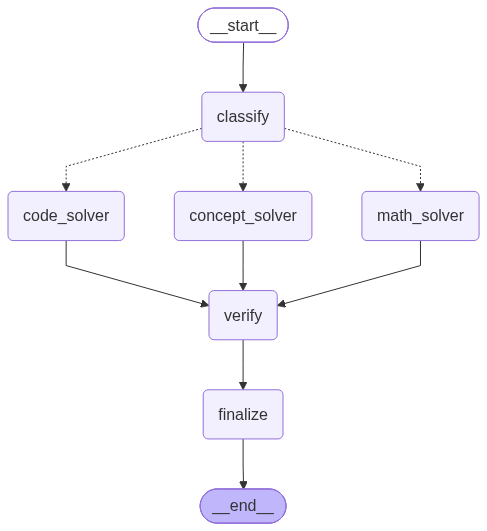



######################################################################
🤖 MULTI-LLM FAILOVER CHATBOT IS ONLINE
######################################################################

You can ask ANY question.

Examples:
  What is a CNN?
  Explain machine learning
  Write Python code for factorial
  What is 25% of 800?
  What is the difference between RAM and ROM?

Commands:
  /normal   -> normal operation
  /fail1    -> simulate LLM 1 failure
  /fail12   -> simulate LLM 1 + LLM 2 failure
  /fail123  -> simulate all 3 failures
  /status   -> show current model status
  exit      -> stop chatbot

######################################################################

You: What is CNN


######################################################################
USER QUESTION
######################################################################
What is CNN

ANSWER GENERATION

   🔵 TRYING LLM 1
      Model : qwen/qwen3.8-27b
      API   : GROQ

   ✅ LLM 1 WORKED
      Model : qwen/qwen3.8-27b


In [ ]:
# ============================================================
# ============================================================
#        3-LLM MULTI-API FAILOVER CHATBOT
#        + LANGGRAPH ANSWER EVALUATOR
# ============================================================
#
# LLM 1 -> Groq   -> qwen/qwen3.8-27b
# LLM 2 -> Groq   -> openai/gpt-oss-120b
# LLM 3 -> Gemini -> gemini-3.8-flash
#
# GENERATION:
# LLM 1 -> LLM 2 -> LLM 3
#
# EVALUATION:
# LLM 2 -> LLM 3 -> LLM 1
#
# ============================================================


# ============================================================
# 1. INSTALL REQUIRED PACKAGES
# ============================================================

!pip install -q -U langgraph langchain-groq langchain-google-genai


# ============================================================
# 2. IMPORTS
# ============================================================

from typing import TypedDict

from google.colab import userdata

from langchain_groq import ChatGroq
from langchain_google_genai import ChatGoogleGenerativeAI

from langgraph.graph import StateGraph, START, END

from IPython.display import Image, display


# ============================================================
# 3. LOAD API KEYS
# ============================================================

GROQ_API_KEY = None
GEMINI_API_KEY = None


# ------------------------------------------------------------
# Groq key
# ------------------------------------------------------------

try:
    GROQ_API_KEY = userdata.get("GROQ_API_KEY")
except:
    pass


# Support GROK_API_KEY too
if not GROQ_API_KEY:

    try:
        GROQ_API_KEY = userdata.get("GROK_API_KEY")
    except:
        pass


# ------------------------------------------------------------
# Gemini key
# ------------------------------------------------------------

try:
    GEMINI_API_KEY = userdata.get("gemini")
except:
    pass


# ------------------------------------------------------------
# Check keys
# ------------------------------------------------------------

if not GROQ_API_KEY:

    raise ValueError(
        """
GROQ API KEY NOT FOUND.

Go to:
Colab -> Secrets

Create:

GROQ_API_KEY
"""
    )


if not GEMINI_API_KEY:

    raise ValueError(
        """
GEMINI API KEY NOT FOUND.

Go to:
Colab -> Secrets

Create:

GEMINI_API_KEY
"""
    )


print("=" * 70)
print("API KEY STATUS")
print("=" * 70)

print("Groq   : READY")
print("Gemini : READY")

print("=" * 70)


# ============================================================
# 4. MODEL NAMES
# ============================================================

MODEL_1 = "qwen/qwen3.8-27b"

MODEL_2 = "openai/gpt-oss-120b"

MODEL_3 = "gemini-3.8-flash"


# ============================================================
# 5. CREATE LLM 1
# ============================================================

llm1 = ChatGroq(
    model=MODEL_1,
    groq_api_key=GROQ_API_KEY,
    temperature=0
)


# ============================================================
# 6. CREATE LLM 2
# ============================================================

llm2 = ChatGroq(
    model=MODEL_2,
    groq_api_key=GROQ_API_KEY,
    temperature=0
)


# ============================================================
# 7. CREATE LLM 3
# ============================================================

llm3 = ChatGoogleGenerativeAI(
    model=MODEL_3,
    google_api_key=GEMINI_API_KEY,
    temperature=0
)


# ============================================================
# 8. MODEL REGISTRY
# ============================================================

MODELS = {

    "LLM 1": {
        "model": MODEL_1,
        "provider": "GROQ",
        "llm": llm1
    },

    "LLM 2": {
        "model": MODEL_2,
        "provider": "GROQ",
        "llm": llm2
    },

    "LLM 3": {
        "model": MODEL_3,
        "provider": "GEMINI",
        "llm": llm3
    }

}


# ============================================================
# 9. DISPLAY MODELS
# ============================================================

print()
print("=" * 70)
print("THREE LLMs / TWO APIs")
print("=" * 70)

for name, info in MODELS.items():

    print()
    print(name)
    print("  Model :", info["model"])
    print("  API   :", info["provider"])

print()
print("=" * 70)


# ============================================================
# 10. FAILURE SIMULATION
# ============================================================
#
# Normally:
#
# FAIL_MODELS = []
#
# Special commands in chatbot can change this automatically.
#
# /fail1
#     LLM 1 fails -> LLM 2 takes over
#
# /fail12
#     LLM 1 fails -> LLM 2 fails -> LLM 3 takes over
#
# /fail123
#     All three fail
#
# /normal
#     Return to normal operation
#
# ============================================================

FAIL_MODELS = []


# ============================================================
# 11. CLEAN MODEL RESPONSE
# ============================================================

def clean_response(response):

    if hasattr(response, "content"):

        content = response.content

    else:

        content = str(response)


    if isinstance(content, list):

        parts = []

        for item in content:

            if isinstance(item, dict):

                if "text" in item:

                    parts.append(
                        str(item["text"])
                    )

            else:

                parts.append(
                    str(item)
                )

        content = "\n".join(parts)


    return str(content).strip()


# ============================================================
# 12. CALL ONE MODEL
# ============================================================

def call_model(model_key, prompt):

    info = MODELS[model_key]

    model = info["llm"]

    model_name = info["model"]

    provider = info["provider"]


    # --------------------------------------------------------
    # SIMULATED FAILURE
    # --------------------------------------------------------

    if model_key in FAIL_MODELS:

        print()
        print(
            f"   ❌ {model_key} "
            f"SIMULATED FAILURE"
        )

        raise RuntimeError(
            f"Simulated failure: {model_key}"
        )


    # --------------------------------------------------------
    # REAL API CALL
    # --------------------------------------------------------

    print()
    print(
        f"   🔵 TRYING {model_key}"
    )

    print(
        f"      Model : {model_name}"
    )

    print(
        f"      API   : {provider}"
    )


    try:

        response = model.invoke(prompt)

        answer = clean_response(response)


        if not answer:

            raise RuntimeError(
                "Empty response received."
            )


        print()
        print(
            f"   ✅ {model_key} WORKED"
        )

        print(
            f"      Model : {model_name}"
        )

        print(
            f"      API   : {provider}"
        )


        return answer


    except Exception as error:

        print()
        print(
            f"   ❌ {model_key} FAILED"
        )

        print(
            "      Error:",
            str(error)[:300]
        )

        raise


# ============================================================
# 13. AUTOMATIC FAILOVER
# ============================================================

def automatic_failover(prompt, order):

    errors = []


    for model_key in order:

        try:

            answer = call_model(
                model_key,
                prompt
            )


            return answer, model_key


        except Exception as error:

            errors.append(
                f"{model_key}: {str(error)}"
            )


            print()
            print(
                f"   🔄 SWITCHING FROM {model_key}"
            )

            continue


    # --------------------------------------------------------
    # ALL MODELS FAILED
    # --------------------------------------------------------

    print()
    print("=" * 70)
    print("❌ ALL AVAILABLE MODELS FAILED")
    print("=" * 70)


    raise RuntimeError(
        "All models failed."
    )


# ============================================================
# 14. GENERATE CHATBOT ANSWER
# ============================================================

def generate_answer(question):

    print()
    print("=" * 70)
    print("ANSWER GENERATION")
    print("=" * 70)


    prompt = f"""
You are the main AI assistant.

Answer the user's question clearly, accurately and helpfully.

USER QUESTION:
{question}

Instructions:

1. Answer the question directly.
2. Explain when necessary.
3. If the user asks for code, provide useful code.
4. If the user asks a mathematical question, calculate it carefully.
5. If the user asks a conceptual question, explain it clearly.
6. Do not mention this failover system.
7. Do not mention other models.
"""


    answer, model_used = automatic_failover(

        prompt,

        [
            "LLM 1",
            "LLM 2",
            "LLM 3"
        ]

    )


    return answer, model_used


# ============================================================
# 15. LANGGRAPH STATE
# ============================================================

class AgentState(TypedDict):

    question: str

    original_answer: str

    generator_model: str

    category: str

    reasoning: str

    verdict: str

    feedback: str

    evaluator_model: str

    final: str


# ============================================================
# 16. CLASSIFY QUESTION
# ============================================================

def classify_node(state):

    print()
    print("=" * 70)
    print("LANGGRAPH -> CLASSIFICATION")
    print("=" * 70)


    prompt = f"""
You are an evaluator.

USER QUESTION:
{state['question']}

AI ANSWER:
{state['original_answer']}

Classify the question into exactly one category:

MATH
CONCEPT
CODE

Return only one word.
"""


    try:

        result, model_used = automatic_failover(

            prompt,

            [
                "LLM 2",
                "LLM 3",
                "LLM 1"
            ]

        )


        result_upper = result.upper()


        if "MATH" in result_upper:

            category = "math"

        elif "CODE" in result_upper:

            category = "code"

        else:

            category = "concept"


        state["category"] = category

        state["evaluator_model"] = model_used


        print()
        print(
            "CATEGORY:",
            category
        )

        print(
            "CLASSIFIED BY:",
            model_used
        )


    except Exception:

        # If classification itself fails,
        # continue with a general concept evaluator.

        state["category"] = "concept"

        state["evaluator_model"] = "None"


        print()
        print(
            "⚠ Classification unavailable."
        )

        print(
            "Continuing with general evaluation."
        )


    return state


# ============================================================
# 17. ROUTE CATEGORY
# ============================================================

def route_category(state):

    if state["category"] == "math":

        return "math_solver"


    elif state["category"] == "code":

        return "code_solver"


    else:

        return "concept_solver"


# ============================================================
# 18. MATH EVALUATOR
# ============================================================

def math_solver(state):

    print()
    print("=" * 70)
    print("LANGGRAPH -> MATH EVALUATOR")
    print("=" * 70)


    prompt = f"""
You are a strict mathematics evaluator.

QUESTION:
{state['question']}

AI ANSWER:
{state['original_answer']}

Solve the problem yourself.

Check whether the AI answer is correct.

Return:

CORRECT: YES

or

CORRECT: NO

Then explain briefly.
"""


    try:

        result, model_used = automatic_failover(

            prompt,

            [
                "LLM 2",
                "LLM 3",
                "LLM 1"
            ]

        )


        state["reasoning"] = result

        state["evaluator_model"] = model_used


    except Exception:

        state["reasoning"] = (
            "Evaluation could not be completed "
            "because all evaluator models failed."
        )


    return state


# ============================================================
# 19. CONCEPT EVALUATOR
# ============================================================

def concept_solver(state):

    print()
    print("=" * 70)
    print("LANGGRAPH -> CONCEPT EVALUATOR")
    print("=" * 70)


    prompt = f"""
You are a strict factual evaluator.

QUESTION:
{state['question']}

AI ANSWER:
{state['original_answer']}

Determine whether the answer is factually reasonable.

Return:

CORRECT: YES

or

CORRECT: NO

Then explain briefly.
"""


    try:

        result, model_used = automatic_failover(

            prompt,

            [
                "LLM 2",
                "LLM 3",
                "LLM 1"
            ]

        )


        state["reasoning"] = result

        state["evaluator_model"] = model_used


    except Exception:

        state["reasoning"] = (
            "Evaluation could not be completed "
            "because all evaluator models failed."
        )


    return state


# ============================================================
# 20. CODE EVALUATOR
# ============================================================

def code_solver(state):

    print()
    print("=" * 70)
    print("LANGGRAPH -> CODE EVALUATOR")
    print("=" * 70)


    prompt = f"""
You are a strict programming evaluator.

QUESTION:
{state['question']}

AI ANSWER:
{state['original_answer']}

Check whether the answer solves the requested programming problem.

Check for obvious syntax and logic errors.

Return:

CORRECT: YES

or

CORRECT: NO

Then explain briefly.
"""


    try:

        result, model_used = automatic_failover(

            prompt,

            [
                "LLM 2",
                "LLM 3",
                "LLM 1"
            ]

        )


        state["reasoning"] = result

        state["evaluator_model"] = model_used


    except Exception:

        state["reasoning"] = (
            "Evaluation could not be completed "
            "because all evaluator models failed."
        )


    return state


# ============================================================
# 21. FINAL VERIFICATION
# ============================================================

def verify_node(state):

    print()
    print("=" * 70)
    print("LANGGRAPH -> FINAL VERIFICATION")
    print("=" * 70)


    # If evaluator failed completely
    if (
        not state["reasoning"]
        or
        "could not be completed" in state["reasoning"]
    ):

        state["verdict"] = "UNVERIFIED"

        state["feedback"] = (
            "The answer was generated successfully, "
            "but the evaluator models were unavailable."
        )

        return state


    prompt = f"""
You are the final answer verifier.

QUESTION:
{state['question']}

ORIGINAL AI ANSWER:
{state['original_answer']}

EVALUATOR ANALYSIS:
{state['reasoning']}

Determine whether the original answer is acceptable.

Return:

VERDICT: PASS

if the answer is correct.

Return:

VERDICT: FAIL

if the answer has a significant error.

Then provide a short explanation.
"""


    try:

        result, model_used = automatic_failover(

            prompt,

            [
                "LLM 2",
                "LLM 3",
                "LLM 1"
            ]

        )


        result_upper = result.upper()


        if "VERDICT: FAIL" in result_upper:

            verdict = "FAIL"

        elif "VERDICT: PASS" in result_upper:

            verdict = "PASS"

        elif "FAIL" in result_upper:

            verdict = "FAIL"

        else:

            verdict = "PASS"


        state["verdict"] = verdict

        state["feedback"] = result

        state["evaluator_model"] = model_used


    except Exception:

        state["verdict"] = "UNVERIFIED"

        state["feedback"] = (
            "The answer was generated successfully, "
            "but final verification was unavailable."
        )


    return state


# ============================================================
# 22. FINALIZE
# ============================================================

def finalize_node(state):

    print()
    print("=" * 70)
    print("LANGGRAPH -> FINAL")
    print("=" * 70)


    state["final"] = state["original_answer"]


    return state


# ============================================================
# 23. BUILD LANGGRAPH
# ============================================================

builder = StateGraph(
    AgentState
)


# Nodes

builder.add_node(
    "classify",
    classify_node
)

builder.add_node(
    "math_solver",
    math_solver
)

builder.add_node(
    "concept_solver",
    concept_solver
)

builder.add_node(
    "code_solver",
    code_solver
)

builder.add_node(
    "verify",
    verify_node
)

builder.add_node(
    "finalize",
    finalize_node
)


# ============================================================
# 24. GRAPH EDGES
# ============================================================

builder.add_edge(
    START,
    "classify"
)


builder.add_conditional_edges(
    "classify",
    route_category,
    [
        "math_solver",
        "concept_solver",
        "code_solver"
    ]
)


builder.add_edge(
    "math_solver",
    "verify"
)

builder.add_edge(
    "concept_solver",
    "verify"
)

builder.add_edge(
    "code_solver",
    "verify"
)


builder.add_edge(
    "verify",
    "finalize"
)


builder.add_edge(
    "finalize",
    END
)


# ============================================================
# 25. COMPILE
# ============================================================

app = builder.compile()


# ============================================================
# 26. DISPLAY GRAPH
# ============================================================

print()
print("=" * 70)
print("LANGGRAPH STRUCTURE")
print("=" * 70)


try:

    graph_png = app.get_graph().draw_mermaid_png()

    display(
        Image(graph_png)
    )

except Exception:

    print(
        app.get_graph().draw_mermaid()
    )


# ============================================================
# 27. RUN CHATBOT QUESTION
# ============================================================

def process_question(question):

    print()
    print()
    print("#" * 70)
    print("USER QUESTION")
    print("#" * 70)

    print(question)


    # --------------------------------------------------------
    # GENERATE ANSWER
    # --------------------------------------------------------

    try:

        answer, generator_model = generate_answer(
            question
        )

    except Exception as error:

        print()
        print("=" * 70)
        print("❌ COMPLETE GENERATION FAILURE")
        print("=" * 70)

        print(
            "All three generation models failed."
        )

        print(
            str(error)[:500]
        )

        return


    # --------------------------------------------------------
    # DISPLAY ANSWER
    # --------------------------------------------------------

    print()
    print("#" * 70)
    print("AI ANSWER")
    print("#" * 70)

    print(answer)


    print()
    print(
        "Generated by:",
        generator_model
    )


    # --------------------------------------------------------
    # LANGGRAPH EVALUATION
    # --------------------------------------------------------

    initial_state = {

        "question": question,

        "original_answer": answer,

        "generator_model": generator_model,

        "category": "",

        "reasoning": "",

        "verdict": "",

        "feedback": "",

        "evaluator_model": "",

        "final": ""
    }


    try:

        result = app.invoke(
            initial_state
        )


    except Exception as error:

        print()
        print(
            "⚠ LangGraph evaluation failed."
        )

        print(
            "The generated answer is still available."
        )

        return


    # --------------------------------------------------------
    # VERIFICATION INFORMATION
    # --------------------------------------------------------

    print()
    print("=" * 70)
    print("EVALUATION RESULT")
    print("=" * 70)

    print(
        "Generator :",
        result["generator_model"]
    )

    print(
        "Category  :",
        result["category"]
    )

    print(
        "Evaluator :",
        result["evaluator_model"]
    )

    print(
        "Verdict   :",
        result["verdict"]
    )

    print("=" * 70)


# ============================================================
# 28. INTERACTIVE CHATBOT
# ============================================================

print()
print()
print("#" * 70)
print("🤖 MULTI-LLM FAILOVER CHATBOT IS ONLINE")
print("#" * 70)

print()
print("You can ask ANY question.")
print()
print("Examples:")
print("  What is a CNN?")
print("  Explain machine learning")
print("  Write Python code for factorial")
print("  What is 25% of 800?")
print("  What is the difference between RAM and ROM?")
print()
print("Commands:")
print("  /normal   -> normal operation")
print("  /fail1    -> simulate LLM 1 failure")
print("  /fail12   -> simulate LLM 1 + LLM 2 failure")
print("  /fail123  -> simulate all 3 failures")
print("  /status   -> show current model status")
print("  exit      -> stop chatbot")
print()
print("#" * 70)


# ============================================================
# 29. CHAT LOOP
# ============================================================

while True:

    print()

    question = input("You: ").strip()


    # --------------------------------------------------------
    # EXIT
    # --------------------------------------------------------

    if question.lower() in [
        "exit",
        "quit",
        "bye"
    ]:

        print()
        print("Chatbot stopped.")
        break


    # --------------------------------------------------------
    # EMPTY INPUT
    # --------------------------------------------------------

    if not question:

        print(
            "Please enter a question."
        )

        continue


    # --------------------------------------------------------
    # NORMAL MODE
    # --------------------------------------------------------

    if question.lower() == "/normal":

        FAIL_MODELS = []

        print()
        print("✅ NORMAL MODE ENABLED")

        print(
            "Order: LLM 1 -> LLM 2 -> LLM 3"
        )

        continue


    # --------------------------------------------------------
    # FAIL LLM 1
    # --------------------------------------------------------

    if question.lower() == "/fail1":

        FAIL_MODELS = [
            "LLM 1"
        ]

        print()
        print("⚠ TEST MODE ENABLED")

        print(
            "LLM 1 will fail."
        )

        print(
            "LLM 2 should take over."
        )

        continue


    # --------------------------------------------------------
    # FAIL LLM 1 + LLM 2
    # --------------------------------------------------------

    if question.lower() == "/fail12":

        FAIL_MODELS = [
            "LLM 1",
            "LLM 2"
        ]

        print()
        print("⚠ TEST MODE ENABLED")

        print(
            "LLM 1 will fail."
        )

        print(
            "LLM 2 will fail."
        )

        print(
            "LLM 3 / Gemini should take over."
        )

        continue


    # --------------------------------------------------------
    # FAIL ALL 3
    # --------------------------------------------------------

    if question.lower() == "/fail123":

        FAIL_MODELS = [
            "LLM 1",
            "LLM 2",
            "LLM 3"
        ]

        print()
        print("⚠ ALL-MODEL FAILURE TEST ENABLED")

        print(
            "LLM 1 -> FAIL"
        )

        print(
            "LLM 2 -> FAIL"
        )

        print(
            "LLM 3 -> FAIL"
        )

        continue


    # --------------------------------------------------------
    # STATUS
    # --------------------------------------------------------

    if question.lower() == "/status":

        print()
        print("=" * 70)
        print("CURRENT SYSTEM STATUS")
        print("=" * 70)

        print()
        print("LLM 1:")
        print(
            MODEL_1,
            "-> GROQ"
        )

        print()
        print("LLM 2:")
        print(
            MODEL_2,
            "-> GROQ"
        )

        print()
        print("LLM 3:")
        print(
            MODEL_3,
            "-> GEMINI"
        )

        print()
        print("Current simulated failures:")

        if FAIL_MODELS:

            for model in FAIL_MODELS:

                print(
                    "  ❌",
                    model
                )

        else:

            print(
                "  None"
            )

        print()
        print("Generation order:")
        print(
            "LLM 1 -> LLM 2 -> LLM 3"
        )

        print()
        print("Evaluation order:")
        print(
            "LLM 2 -> LLM 3 -> LLM 1"
        )

        print(
            "=" * 70
        )

        continue


    # --------------------------------------------------------
    # NORMAL QUESTION
    # --------------------------------------------------------

    process_question(
        question
    )

LOADING API KEYS
Groq      : READY
Gemini    : READY
LangSmith : READY

LangSmith Project:
3-LLM Multi-API Failover Chatbot

CREATING THREE LLMs

Creating LLM 1...
LLM 1 READY

Creating LLM 2...
LLM 2 READY

Creating LLM 3...
LLM 3 READY

THREE LLMs / TWO APIs

LLM 1
  Model : qwen/qwen3-32b
  API   : GROQ

LLM 2
  Model : openai/gpt-oss-120b
  API   : GROQ

LLM 3
  Model : gemini-3.8-flash
  API   : GEMINI

BUILDING LANGGRAPH
LANGGRAPH COMPILED SUCCESSFULLY!

LANGGRAPH STRUCTURE

Graph nodes:
['__start__', 'classify', 'math_solver', 'concept_solver', 'code_solver', 'verify', 'finalize', '__end__']

Graph edges:
[Edge(source='__start__', target='classify', data=None, conditional=False), Edge(source='classify', target='code_solver', data=None, conditional=True), Edge(source='classify', target='concept_solver', data=None, conditional=True), Edge(source='classify', target='math_solver', data=None, conditional=True), Edge(source='code_solver', target='verify', data=None, conditional=False)

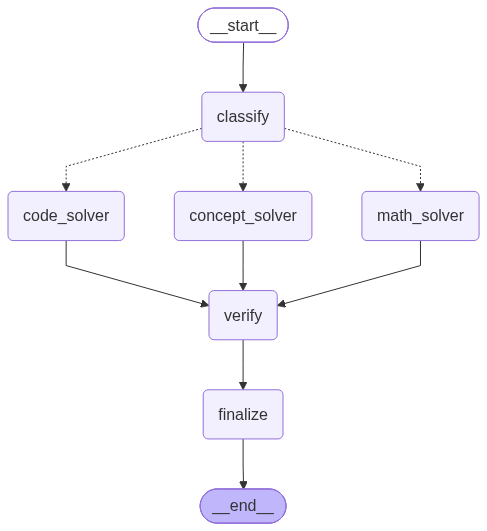


Graph displayed successfully!

🤖 MULTI-LLM FAILOVER CHATBOT IS ONLINE

Commands:

/normal   -> Normal mode
/fail1    -> Simulate LLM 1 failure
/fail12   -> Simulate LLM 1 and LLM 2 failure
/fail123  -> Simulate all LLM failures
/status   -> Show current mode
/exit     -> Exit chatbot


You: What is 25% of 800?

Running LangGraph...

----------------------------------------------------------------------
CLASSIFY NODE
----------------------------------------------------------------------
Question : What is 25% of 800?
Category : concept

----------------------------------------------------------------------
CONCEPT SOLVER
----------------------------------------------------------------------
Trying: LLM 1
FAILED: LLM 1
Error: Error code: 404 - {'error': {'message': 'The model `qwen/qwen3-32b` does not exist or you do not have access to it.', 'type': 'invalid_request_error',
Trying: LLM 2
SUCCESS: LLM 2

----------------------------------------------------------------------
VERIFY NODE
-

In [ ]:
# ================================================================
# 3-LLM MULTI-API FAILOVER CHATBOT
# LANGGRAPH + LANGSMITH
# ================================================================

!pip install -q -U langgraph langchain-groq langchain-google-genai langsmith

# ================================================================
# IMPORTS
# ================================================================

from typing import TypedDict
from google.colab import userdata
from langchain_groq import ChatGroq
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display
import os


# ================================================================
# API KEYS
# ================================================================

print("=" * 70)
print("LOADING API KEYS")
print("=" * 70)

# ---------- GROQ ----------
GROQ_API_KEY = None

try:
    GROQ_API_KEY = userdata.get("GROQ_API_KEY")
except:
    pass

if not GROQ_API_KEY:
    try:
        GROQ_API_KEY = userdata.get("GROK_API_KEY")
    except:
        pass


# ---------- GEMINI ----------
GEMINI_API_KEY = None

try:
    GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")
except:
    pass

if not GEMINI_API_KEY:
    try:
        GEMINI_API_KEY = userdata.get("gemini")
    except:
        pass


# ---------- LANGSMITH ----------
# Your LangSmith secret is named "api"
LANGSMITH_API_KEY = None

try:
    LANGSMITH_API_KEY = userdata.get("API")
except:
    pass


# ================================================================
# CHECK KEYS
# ================================================================

if not GROQ_API_KEY:
    raise ValueError(
        "GROQ API KEY NOT FOUND.\n"
        "Add your Groq key to Colab Secrets as GROQ_API_KEY"
    )

if not GEMINI_API_KEY:
    raise ValueError(
        "GEMINI API KEY NOT FOUND.\n"
        "Add your Gemini key to Colab Secrets as GEMINI_API_KEY"
    )

if not LANGSMITH_API_KEY:
    raise ValueError(
        "LANGSMITH API KEY NOT FOUND.\n"
        "Your LangSmith secret should be named: api"
    )


print("Groq      : READY")
print("Gemini    : READY")
print("LangSmith : READY")


# ================================================================
# LANGSMITH CONFIGURATION
# ================================================================

os.environ["LANGSMITH_API_KEY"] = LANGSMITH_API_KEY
os.environ["LANGSMITH_TRACING"] = "true"
os.environ["LANGCHAIN_TRACING_V2"] = "true"
os.environ["LANGSMITH_PROJECT"] = "3-LLM Multi-API Failover Chatbot"

print()
print("LangSmith Project:")
print("3-LLM Multi-API Failover Chatbot")


# ================================================================
# MODEL NAMES
# ================================================================

MODEL_1 = "qwen/qwen3-32b"
MODEL_2 = "openai/gpt-oss-120b"
MODEL_3 = "gemini-3.8-flash"


# ================================================================
# CREATE LLMs
# ================================================================

print()
print("=" * 70)
print("CREATING THREE LLMs")
print("=" * 70)

print("\nCreating LLM 1...")
llm1 = ChatGroq(
    model=MODEL_1,
    groq_api_key=GROQ_API_KEY,
    temperature=0
)
print("LLM 1 READY")


print("\nCreating LLM 2...")
llm2 = ChatGroq(
    model=MODEL_2,
    groq_api_key=GROQ_API_KEY,
    temperature=0
)
print("LLM 2 READY")


print("\nCreating LLM 3...")
llm3 = ChatGoogleGenerativeAI(
    model=MODEL_3,
    google_api_key=GEMINI_API_KEY,
    temperature=0
)
print("LLM 3 READY")


# ================================================================
# DISPLAY MODEL INFORMATION
# ================================================================

print()
print("=" * 70)
print("THREE LLMs / TWO APIs")
print("=" * 70)

print()
print("LLM 1")
print("  Model :", MODEL_1)
print("  API   : GROQ")

print()
print("LLM 2")
print("  Model :", MODEL_2)
print("  API   : GROQ")

print()
print("LLM 3")
print("  Model :", MODEL_3)
print("  API   : GEMINI")


# ================================================================
# GRAPH STATE
# ================================================================

class ChatState(TypedDict):
    question: str
    category: str
    answer: str
    model_used: str
    status: str


# ================================================================
# FAILURE SIMULATION
# ================================================================

failure_mode = "none"


# ================================================================
# CLASSIFY NODE
# ================================================================

def classify(state: ChatState):

    question = state["question"].lower()

    print("\n" + "-" * 70)
    print("CLASSIFY NODE")
    print("-" * 70)

    if any(word in question for word in [
        "calculate",
        "percentage",
        "percent",
        "average",
        "speed",
        "distance",
        "time",
        "sum",
        "subtract",
        "multiply",
        "divide",
        "+",
        "-",
        "*",
        "/"
    ]):
        category = "math"

    elif any(word in question for word in [
        "python",
        "java",
        "code",
        "program",
        "programming",
        "javascript",
        "error",
        "function"
    ]):
        category = "code"

    else:
        category = "concept"

    print("Question :", state["question"])
    print("Category :", category)

    return {
        "category": category
    }


# ================================================================
# MATH SOLVER
# ================================================================

def math_solver(state: ChatState):

    question = state["question"]

    print("\n" + "-" * 70)
    print("MATH SOLVER")
    print("-" * 70)

    models = [
        ("LLM 1", llm1),
        ("LLM 2", llm2),
        ("LLM 3", llm3)
    ]

    # Simulated failures
    if failure_mode == "fail1":
        models = models[1:]

    elif failure_mode == "fail12":
        models = models[2:]

    elif failure_mode == "fail123":
        models = []

    for name, model in models:

        try:

            print("Trying:", name)

            response = model.invoke(
                f"Solve this math problem clearly:\n{question}"
            )

            answer = response.content

            print("SUCCESS:", name)

            return {
                "answer": answer,
                "model_used": name,
                "status": "success"
            }

        except Exception as e:

            print("FAILED:", name)
            print("Error:", str(e)[:150])

    return {
        "answer": "All available models failed.",
        "model_used": "None",
        "status": "failed"
    }


# ================================================================
# CONCEPT SOLVER
# ================================================================

def concept_solver(state: ChatState):

    question = state["question"]

    print("\n" + "-" * 70)
    print("CONCEPT SOLVER")
    print("-" * 70)

    models = [
        ("LLM 1", llm1),
        ("LLM 2", llm2),
        ("LLM 3", llm3)
    ]

    if failure_mode == "fail1":
        models = models[1:]

    elif failure_mode == "fail12":
        models = models[2:]

    elif failure_mode == "fail123":
        models = []

    for name, model in models:

        try:

            print("Trying:", name)

            response = model.invoke(
                f"Answer this question clearly and simply:\n{question}"
            )

            answer = response.content

            print("SUCCESS:", name)

            return {
                "answer": answer,
                "model_used": name,
                "status": "success"
            }

        except Exception as e:

            print("FAILED:", name)
            print("Error:", str(e)[:150])

    return {
        "answer": "All available models failed.",
        "model_used": "None",
        "status": "failed"
    }


# ================================================================
# CODE SOLVER
# ================================================================

def code_solver(state: ChatState):

    question = state["question"]

    print("\n" + "-" * 70)
    print("CODE SOLVER")
    print("-" * 70)

    models = [
        ("LLM 1", llm1),
        ("LLM 2", llm2),
        ("LLM 3", llm3)
    ]

    if failure_mode == "fail1":
        models = models[1:]

    elif failure_mode == "fail12":
        models = models[2:]

    elif failure_mode == "fail123":
        models = []

    for name, model in models:

        try:

            print("Trying:", name)

            response = model.invoke(
                f"Answer this programming question with explanation and code if needed:\n{question}"
            )

            answer = response.content

            print("SUCCESS:", name)

            return {
                "answer": answer,
                "model_used": name,
                "status": "success"
            }

        except Exception as e:

            print("FAILED:", name)
            print("Error:", str(e)[:150])

    return {
        "answer": "All available models failed.",
        "model_used": "None",
        "status": "failed"
    }


# ================================================================
# VERIFY NODE
# ================================================================

def verify(state: ChatState):

    print("\n" + "-" * 70)
    print("VERIFY NODE")
    print("-" * 70)

    if state.get("status") == "success":
        print("Answer verified.")
    else:
        print("Verification: FAILED")

    return state


# ================================================================
# FINALIZE NODE
# ================================================================

def finalize(state: ChatState):

    print("\n" + "-" * 70)
    print("FINALIZE NODE")
    print("-" * 70)

    return state


# ================================================================
# ROUTING FUNCTION
# ================================================================

def route_question(state: ChatState):

    category = state["category"]

    if category == "math":
        return "math_solver"

    elif category == "code":
        return "code_solver"

    else:
        return "concept_solver"


# ================================================================
# BUILD LANGGRAPH
# ================================================================

print()
print("=" * 70)
print("BUILDING LANGGRAPH")
print("=" * 70)

builder = StateGraph(ChatState)

builder.add_node("classify", classify)
builder.add_node("math_solver", math_solver)
builder.add_node("concept_solver", concept_solver)
builder.add_node("code_solver", code_solver)
builder.add_node("verify", verify)
builder.add_node("finalize", finalize)


builder.add_edge(START, "classify")

builder.add_conditional_edges(
    "classify",
    route_question,
    {
        "math_solver": "math_solver",
        "concept_solver": "concept_solver",
        "code_solver": "code_solver"
    }
)

builder.add_edge("math_solver", "verify")
builder.add_edge("concept_solver", "verify")
builder.add_edge("code_solver", "verify")

builder.add_edge("verify", "finalize")
builder.add_edge("finalize", END)


app = builder.compile()

print("LANGGRAPH COMPILED SUCCESSFULLY!")


# ================================================================
# SHOW GRAPH
# ================================================================

print()
print("=" * 70)
print("LANGGRAPH STRUCTURE")
print("=" * 70)

try:

    graph = app.get_graph()

    print("\nGraph nodes:")
    print(list(graph.nodes.keys()))

    print("\nGraph edges:")
    print(list(graph.edges))

    # Try displaying graph
    try:
        graph_image = graph.draw_mermaid_png()
        display(Image(graph_image))
        print("\nGraph displayed successfully!")

    except Exception as graph_error:
        print("\nGraph image could not be displayed.")
        print("But LangGraph itself is working.")
        print("Reason:", str(graph_error)[:200])

except Exception as e:

    print("Graph inspection error:", str(e)[:200])


# ================================================================
# CHATBOT
# ================================================================

print()
print("=" * 70)
print("🤖 MULTI-LLM FAILOVER CHATBOT IS ONLINE")
print("=" * 70)

print("""
Commands:

/normal   -> Normal mode
/fail1    -> Simulate LLM 1 failure
/fail12   -> Simulate LLM 1 and LLM 2 failure
/fail123  -> Simulate all LLM failures
/status   -> Show current mode
/exit     -> Exit chatbot
""")

print("=" * 70)


# ================================================================
# INTERACTIVE LOOP
# ================================================================

while True:

    try:
        user_input = input("\nYou: ").strip()

    except KeyboardInterrupt:
        print("\nChatbot stopped.")
        break

    except EOFError:
        print("\nChatbot stopped.")
        break


    # ------------------------------------------------------------
    # EXIT
    # ------------------------------------------------------------

    if user_input.lower() in ["/exit", "exit", "quit"]:
        print("\nChatbot closed.")
        break


    # ------------------------------------------------------------
    # NORMAL MODE
    # ------------------------------------------------------------

    if user_input.lower() == "/normal":

        failure_mode = "none"

        print("\nMode changed to NORMAL.")
        continue


    # ------------------------------------------------------------
    # FAIL 1
    # ------------------------------------------------------------

    if user_input.lower() == "/fail1":

        failure_mode = "fail1"

        print("\nMode changed to FAIL LLM 1.")
        print("LLM 1 will be skipped.")
        continue


    # ------------------------------------------------------------
    # FAIL 1 + 2
    # ------------------------------------------------------------

    if user_input.lower() == "/fail12":

        failure_mode = "fail12"

        print("\nMode changed to FAIL LLM 1 + LLM 2.")
        print("Only LLM 3 will be used.")
        continue


    # ------------------------------------------------------------
    # FAIL ALL
    # ------------------------------------------------------------

    if user_input.lower() == "/fail123":

        failure_mode = "fail123"

        print("\nMode changed to FAIL ALL.")
        continue


    # ------------------------------------------------------------
    # STATUS
    # ------------------------------------------------------------

    if user_input.lower() == "/status":

        print("\nCurrent failure mode:", failure_mode)

        if failure_mode == "none":
            print("LLM 1 : AVAILABLE")
            print("LLM 2 : AVAILABLE")
            print("LLM 3 : AVAILABLE")

        elif failure_mode == "fail1":
            print("LLM 1 : SIMULATED FAILURE")
            print("LLM 2 : AVAILABLE")
            print("LLM 3 : AVAILABLE")

        elif failure_mode == "fail12":
            print("LLM 1 : SIMULATED FAILURE")
            print("LLM 2 : SIMULATED FAILURE")
            print("LLM 3 : AVAILABLE")

        elif failure_mode == "fail123":
            print("LLM 1 : SIMULATED FAILURE")
            print("LLM 2 : SIMULATED FAILURE")
            print("LLM 3 : SIMULATED FAILURE")

        continue


    # ------------------------------------------------------------
    # EMPTY INPUT
    # ------------------------------------------------------------

    if not user_input:

        print("Please enter a question.")
        continue


    # ------------------------------------------------------------
    # RUN LANGGRAPH
    # ------------------------------------------------------------

    print("\nRunning LangGraph...")

    try:

        result = app.invoke(
            {
                "question": user_input,
                "category": "",
                "answer": "",
                "model_used": "",
                "status": ""
            }
        )

        print()
        print("=" * 70)
        print("FINAL ANSWER")
        print("=" * 70)

        print(result.get("answer", "No answer"))

        print()
        print("Model used:", result.get("model_used", "Unknown"))
        print("Status:", result.get("status", "Unknown"))

        print("=" * 70)

    except Exception as e:

        print()
        print("=" * 70)
        print("ERROR")
        print("=" * 70)
        print(type(e).__name__)
        print(str(e))
        print("=" * 70)

LOADING API KEYS
Groq      : READY
Gemini    : READY
LangSmith : READY

LANGSMITH CONFIGURATION
Project : 3-LLM Multi-API Failover Chatbot
Tracing : ENABLED
Endpoint: https://api.smith.langchain.com
Tracer  : READY

CREATING THREE LLMs

Creating LLM 1...
LLM 1 READY

Creating LLM 2...
LLM 2 READY

Creating LLM 3...
LLM 3 READY

THREE LLMs / TWO APIs

LLM 1
  Model : llama-3.3-70b-versatile
  API   : GROQ

LLM 2
  Model : openai/gpt-oss-120b
  API   : GROQ

LLM 3
  Model : gemini-2.5-flash
  API   : GEMINI

BUILDING LANGGRAPH
LANGGRAPH COMPILED SUCCESSFULLY!

LANGGRAPH STRUCTURE

Graph nodes:
['__start__', 'classify', 'math_solver', 'concept_solver', 'code_solver', 'verify', 'finalize', '__end__']

Graph edges:
[Edge(source='__start__', target='classify', data=None, conditional=False), Edge(source='classify', target='code_solver', data=None, conditional=True), Edge(source='classify', target='concept_solver', data=None, conditional=True), Edge(source='classify', target='math_solver', dat

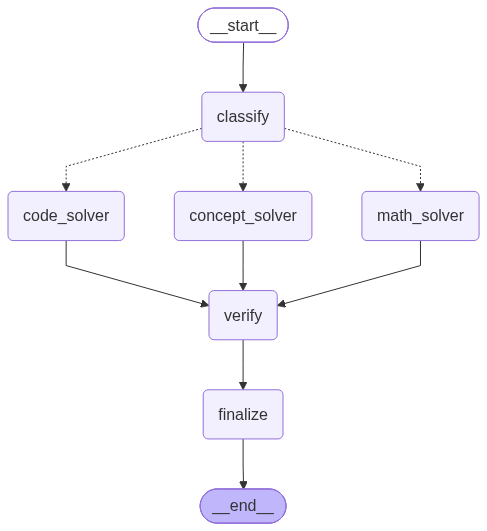


Graph displayed successfully!

🤖 MULTI-LLM FAILOVER CHATBOT IS ONLINE

Commands:

/normal   -> Normal mode
/fail1    -> Simulate LLM 1 failure
/fail12   -> Simulate LLM 1 and LLM 2 failure
/fail123  -> Simulate all LLM failures
/status   -> Show current mode
/exit     -> Exit chatbot


You: What is 25% of 800?

Running LangGraph...
Sending trace to LangSmith...

----------------------------------------------------------------------
CLASSIFY NODE
----------------------------------------------------------------------
Question : What is 25% of 800?
Category : concept

----------------------------------------------------------------------
CONCEPT SOLVER
----------------------------------------------------------------------
Trying: LLM 1
FAILED: LLM 1
Error: Error code: 404 - {'error': {'message': 'The model `llama-3.3-70b-versatile` does not exist or you do not have access to it.', 'type': 'invalid_reques
Trying: LLM 2
SUCCESS: LLM 2

------------------------------------------------------

In [ ]:
# ================================================================
# 3-LLM MULTI-API FAILOVER CHATBOT
# LANGGRAPH + LANGSMITH
# ================================================================

!pip install -q -U langgraph langchain-groq langchain-google-genai langsmith

# ================================================================
# IMPORTS
# ================================================================

from typing import TypedDict
from google.colab import userdata
from langchain_groq import ChatGroq
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.tracers import LangChainTracer
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display
import os


# ================================================================
# API KEYS
# ================================================================

print("=" * 70)
print("LOADING API KEYS")
print("=" * 70)

# ---------- GROQ ----------

GROQ_API_KEY = None

try:
    GROQ_API_KEY = userdata.get("GROQ_API_KEY")
except:
    pass

if not GROQ_API_KEY:
    try:
        GROQ_API_KEY = userdata.get("GROK_API_KEY")
    except:
        pass


# ---------- GEMINI ----------

GEMINI_API_KEY = None

try:
    GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")
except:
    pass

if not GEMINI_API_KEY:
    try:
        GEMINI_API_KEY = userdata.get("gemini")
    except:
        pass


# ---------- LANGSMITH ----------

LANGSMITH_API_KEY = None

try:
    LANGSMITH_API_KEY = userdata.get("API")
except:
    pass


# ================================================================
# CHECK KEYS
# ================================================================

if not GROQ_API_KEY:
    raise ValueError(
        "GROQ API KEY NOT FOUND.\n"
        "Add your Groq key to Colab Secrets as GROQ_API_KEY"
    )

if not GEMINI_API_KEY:
    raise ValueError(
        "GEMINI API KEY NOT FOUND.\n"
        "Add your Gemini key to Colab Secrets as GEMINI_API_KEY"
    )

if not LANGSMITH_API_KEY:
    raise ValueError(
        "LANGSMITH API KEY NOT FOUND.\n"
        "Add your LangSmith key to Colab Secrets as API"
    )


print("Groq      : READY")
print("Gemini    : READY")
print("LangSmith : READY")


# ================================================================
# LANGSMITH CONFIGURATION
# ================================================================

LANGSMITH_PROJECT = "3-LLM Multi-API Failover Chatbot"

os.environ["LANGSMITH_API_KEY"] = LANGSMITH_API_KEY
os.environ["LANGSMITH_ENDPOINT"] = "https://api.smith.langchain.com"
os.environ["LANGSMITH_PROJECT"] = LANGSMITH_PROJECT
os.environ["LANGSMITH_TRACING"] = "true"

print()
print("=" * 70)
print("LANGSMITH CONFIGURATION")
print("=" * 70)

print("Project :", LANGSMITH_PROJECT)
print("Tracing : ENABLED")
print("Endpoint: https://api.smith.langchain.com")


# ================================================================
# EXPLICIT LANGSMITH TRACER
# ================================================================

tracer = LangChainTracer(
    project_name=LANGSMITH_PROJECT
)

print("Tracer  : READY")


# ================================================================
# MODEL NAMES
# ================================================================

# LLM 1 = Groq
MODEL_1 = "llama-3.3-70b-versatile"

# LLM 2 = Groq
MODEL_2 = "openai/gpt-oss-120b"

# LLM 3 = Gemini
MODEL_3 = "gemini-2.5-flash"


# ================================================================
# CREATE LLMs
# ================================================================

print()
print("=" * 70)
print("CREATING THREE LLMs")
print("=" * 70)


print("\nCreating LLM 1...")
llm1 = ChatGroq(
    model=MODEL_1,
    groq_api_key=GROQ_API_KEY,
    temperature=0
)
print("LLM 1 READY")


print("\nCreating LLM 2...")
llm2 = ChatGroq(
    model=MODEL_2,
    groq_api_key=GROQ_API_KEY,
    temperature=0
)
print("LLM 2 READY")


print("\nCreating LLM 3...")
llm3 = ChatGoogleGenerativeAI(
    model=MODEL_3,
    google_api_key=GEMINI_API_KEY,
    temperature=0
)
print("LLM 3 READY")


# ================================================================
# DISPLAY MODEL INFORMATION
# ================================================================

print()
print("=" * 70)
print("THREE LLMs / TWO APIs")
print("=" * 70)

print()
print("LLM 1")
print("  Model :", MODEL_1)
print("  API   : GROQ")

print()
print("LLM 2")
print("  Model :", MODEL_2)
print("  API   : GROQ")

print()
print("LLM 3")
print("  Model :", MODEL_3)
print("  API   : GEMINI")


# ================================================================
# GRAPH STATE
# ================================================================

class ChatState(TypedDict):
    question: str
    category: str
    answer: str
    model_used: str
    status: str


# ================================================================
# FAILURE SIMULATION
# ================================================================

failure_mode = "none"


# ================================================================
# CLASSIFY NODE
# ================================================================

def classify(state: ChatState):

    question = state["question"].lower()

    print("\n" + "-" * 70)
    print("CLASSIFY NODE")
    print("-" * 70)

    if any(word in question for word in [
        "calculate",
        "percentage",
        "percent",
        "average",
        "speed",
        "distance",
        "time",
        "sum",
        "subtract",
        "multiply",
        "divide",
        "+",
        "-",
        "*",
        "/"
    ]):
        category = "math"

    elif any(word in question for word in [
        "python",
        "java",
        "code",
        "program",
        "programming",
        "javascript",
        "error",
        "function"
    ]):
        category = "code"

    else:
        category = "concept"

    print("Question :", state["question"])
    print("Category :", category)

    return {
        "category": category
    }


# ================================================================
# GET AVAILABLE MODELS
# ================================================================

def get_models():

    models = [
        ("LLM 1", llm1),
        ("LLM 2", llm2),
        ("LLM 3", llm3)
    ]

    if failure_mode == "fail1":
        models = models[1:]

    elif failure_mode == "fail12":
        models = models[2:]

    elif failure_mode == "fail123":
        models = []

    return models


# ================================================================
# MATH SOLVER
# ================================================================

def math_solver(state: ChatState):

    question = state["question"]

    print("\n" + "-" * 70)
    print("MATH SOLVER")
    print("-" * 70)

    models = get_models()

    for name, model in models:

        try:

            print("Trying:", name)

            response = model.invoke(
                f"Solve this math problem clearly:\n{question}"
            )

            answer = response.content

            print("SUCCESS:", name)

            return {
                "answer": answer,
                "model_used": name,
                "status": "success"
            }

        except Exception as e:

            print("FAILED:", name)
            print("Error:", str(e)[:150])

    return {
        "answer": "All available models failed.",
        "model_used": "None",
        "status": "failed"
    }


# ================================================================
# CONCEPT SOLVER
# ================================================================

def concept_solver(state: ChatState):

    question = state["question"]

    print("\n" + "-" * 70)
    print("CONCEPT SOLVER")
    print("-" * 70)

    models = get_models()

    for name, model in models:

        try:

            print("Trying:", name)

            response = model.invoke(
                f"Answer this question clearly and simply:\n{question}"
            )

            answer = response.content

            print("SUCCESS:", name)

            return {
                "answer": answer,
                "model_used": name,
                "status": "success"
            }

        except Exception as e:

            print("FAILED:", name)
            print("Error:", str(e)[:150])

    return {
        "answer": "All available models failed.",
        "model_used": "None",
        "status": "failed"
    }


# ================================================================
# CODE SOLVER
# ================================================================

def code_solver(state: ChatState):

    question = state["question"]

    print("\n" + "-" * 70)
    print("CODE SOLVER")
    print("-" * 70)

    models = get_models()

    for name, model in models:

        try:

            print("Trying:", name)

            response = model.invoke(
                f"Answer this programming question with explanation "
                f"and code if needed:\n{question}"
            )

            answer = response.content

            print("SUCCESS:", name)

            return {
                "answer": answer,
                "model_used": name,
                "status": "success"
            }

        except Exception as e:

            print("FAILED:", name)
            print("Error:", str(e)[:150])

    return {
        "answer": "All available models failed.",
        "model_used": "None",
        "status": "failed"
    }


# ================================================================
# VERIFY NODE
# ================================================================

def verify(state: ChatState):

    print("\n" + "-" * 70)
    print("VERIFY NODE")
    print("-" * 70)

    if state.get("status") == "success":
        print("Answer verified.")
    else:
        print("Verification: FAILED")

    return state


# ================================================================
# FINALIZE NODE
# ================================================================

def finalize(state: ChatState):

    print("\n" + "-" * 70)
    print("FINALIZE NODE")
    print("-" * 70)

    return state


# ================================================================
# ROUTING FUNCTION
# ================================================================

def route_question(state: ChatState):

    category = state["category"]

    if category == "math":
        return "math_solver"

    elif category == "code":
        return "code_solver"

    else:
        return "concept_solver"


# ================================================================
# BUILD LANGGRAPH
# ================================================================

print()
print("=" * 70)
print("BUILDING LANGGRAPH")
print("=" * 70)

builder = StateGraph(ChatState)

builder.add_node("classify", classify)
builder.add_node("math_solver", math_solver)
builder.add_node("concept_solver", concept_solver)
builder.add_node("code_solver", code_solver)
builder.add_node("verify", verify)
builder.add_node("finalize", finalize)

builder.add_edge(START, "classify")

builder.add_conditional_edges(
    "classify",
    route_question,
    {
        "math_solver": "math_solver",
        "concept_solver": "concept_solver",
        "code_solver": "code_solver"
    }
)

builder.add_edge("math_solver", "verify")
builder.add_edge("concept_solver", "verify")
builder.add_edge("code_solver", "verify")

builder.add_edge("verify", "finalize")
builder.add_edge("finalize", END)

app = builder.compile()

print("LANGGRAPH COMPILED SUCCESSFULLY!")


# ================================================================
# SHOW GRAPH
# ================================================================

print()
print("=" * 70)
print("LANGGRAPH STRUCTURE")
print("=" * 70)

try:

    graph = app.get_graph()

    print("\nGraph nodes:")
    print(list(graph.nodes.keys()))

    print("\nGraph edges:")
    print(list(graph.edges))

    try:

        graph_image = graph.draw_mermaid_png()

        display(Image(graph_image))

        print("\nGraph displayed successfully!")

    except Exception as graph_error:

        print("\nGraph image could not be displayed.")
        print("But LangGraph itself is working.")
        print("Reason:", str(graph_error)[:200])

except Exception as e:

    print("Graph inspection error:", str(e)[:200])


# ================================================================
# CHATBOT
# ================================================================

print()
print("=" * 70)
print("🤖 MULTI-LLM FAILOVER CHATBOT IS ONLINE")
print("=" * 70)

print("""
Commands:

/normal   -> Normal mode
/fail1    -> Simulate LLM 1 failure
/fail12   -> Simulate LLM 1 and LLM 2 failure
/fail123  -> Simulate all LLM failures
/status   -> Show current mode
/exit     -> Exit chatbot
""")

print("=" * 70)


# ================================================================
# INTERACTIVE LOOP
# ================================================================

while True:

    try:

        user_input = input("\nYou: ").strip()

    except KeyboardInterrupt:

        print("\nChatbot stopped.")
        break

    except EOFError:

        print("\nChatbot stopped.")
        break


    # ------------------------------------------------------------
    # EXIT
    # ------------------------------------------------------------

    if user_input.lower() in ["exit", "quit", "/exit"]:

        print("\nChatbot closed.")
        break


    # ------------------------------------------------------------
    # NORMAL MODE
    # ------------------------------------------------------------

    if user_input.lower() == "/normal":

        failure_mode = "none"

        print("\nMode changed to NORMAL.")
        continue


    # ------------------------------------------------------------
    # FAIL 1
    # ------------------------------------------------------------

    if user_input.lower() == "/fail1":

        failure_mode = "fail1"

        print("\nMode changed to FAIL LLM 1.")
        print("LLM 1 will be skipped.")
        continue


    # ------------------------------------------------------------
    # FAIL 1 + 2
    # ------------------------------------------------------------

    if user_input.lower() == "/fail12":

        failure_mode = "fail12"

        print("\nMode changed to FAIL LLM 1 + LLM 2.")
        print("Only LLM 3 will be used.")
        continue


    # ------------------------------------------------------------
    # FAIL ALL
    # ------------------------------------------------------------

    if user_input.lower() == "/fail123":

        failure_mode = "fail123"

        print("\nMode changed to FAIL ALL.")
        continue


    # ------------------------------------------------------------
    # STATUS
    # ------------------------------------------------------------

    if user_input.lower() == "/status":

        print("\nCurrent failure mode:", failure_mode)

        if failure_mode == "none":

            print("LLM 1 : AVAILABLE")
            print("LLM 2 : AVAILABLE")
            print("LLM 3 : AVAILABLE")

        elif failure_mode == "fail1":

            print("LLM 1 : SIMULATED FAILURE")
            print("LLM 2 : AVAILABLE")
            print("LLM 3 : AVAILABLE")

        elif failure_mode == "fail12":

            print("LLM 1 : SIMULATED FAILURE")
            print("LLM 2 : SIMULATED FAILURE")
            print("LLM 3 : AVAILABLE")

        elif failure_mode == "fail123":

            print("LLM 1 : SIMULATED FAILURE")
            print("LLM 2 : SIMULATED FAILURE")
            print("LLM 3 : SIMULATED FAILURE")

        continue


    # ------------------------------------------------------------
    # EMPTY INPUT
    # ------------------------------------------------------------

    if not user_input:

        print("Please enter a question.")
        continue


    # ------------------------------------------------------------
    # RUN LANGGRAPH + LANGSMITH
    # ------------------------------------------------------------

    print("\nRunning LangGraph...")
    print("Sending trace to LangSmith...")

    try:

        result = app.invoke(
            {
                "question": user_input,
                "category": "",
                "answer": "",
                "model_used": "",
                "status": ""
            },
            config={
                "callbacks": [tracer],
                "run_name": "3-LLM Failover Chatbot"
            }
        )

        print()
        print("=" * 70)
        print("FINAL ANSWER")
        print("=" * 70)

        print(result.get("answer", "No answer"))

        print()
        print("Model used:", result.get("model_used", "Unknown"))
        print("Status:", result.get("status", "Unknown"))

        print()
        print("✅ LangSmith trace submitted.")
        print("Project:", LANGSMITH_PROJECT)

        print("=" * 70)

    except Exception as e:

        print()
        print("=" * 70)
        print("ERROR")
        print("=" * 70)

        print(type(e).__name__)
        print(str(e))

        print("=" * 70)

In [ ]:
import os
from google.colab import userdata

# Get your LangSmith key from Colab Secrets
LANGSMITH_API_KEY = userdata.get("API")

# Configure LangSmith BEFORE creating any LLMs
os.environ["LANGSMITH_API_KEY"] = LANGSMITH_API_KEY
os.environ["LANGSMITH_TRACING"] = "true"
os.environ["LANGCHAIN_TRACING_V2"] = "true"
os.environ["LANGSMITH_PROJECT"] = "3-LLM Multi-API Failover Chatbot"

print("LangSmith key found:", bool(LANGSMITH_API_KEY))
print("Tracing:", os.environ.get("LANGSMITH_TRACING"))
print("Project:", os.environ.get("LANGSMITH_PROJECT"))

LangSmith key found: True
Tracing: true
Project: 3-LLM Multi-API Failover Chatbot


In [ ]:
from langchain_groq import ChatGroq
from google.colab import userdata

print("Creating Groq test model...")

test_llm = ChatGroq(
    model="openai/gpt-oss-120b",
    groq_api_key=userdata.get("GROK_API_KEY"),
    temperature=0
)

print("Sending test request...")

response = test_llm.invoke(
    "Say hello in one short sentence."
)

print("\nResponse received:")
print(response.content)

Creating Groq test model...
Sending test request...

Response received:
Hello!


In [ ]:
from langsmith import Client
from google.colab import userdata
import os

print("Checking LangSmith...")

LANGSMITH_API_KEY = userdata.get("API")

os.environ["LANGSMITH_API_KEY"] = LANGSMITH_API_KEY
os.environ["LANGSMITH_TRACING"] = "true"
os.environ["LANGCHAIN_TRACING_V2"] = "true"
os.environ["LANGSMITH_PROJECT"] = "3-LLM Multi-API Failover Chatbot"

client = Client(api_key=LANGSMITH_API_KEY)

print("LangSmith connection: OK")
print("Project: 3-LLM Multi-API Failover Chatbot")

print("\nSending another traced request...")

response = test_llm.invoke(
    "What is 10 + 20?"
)

print("LLM response:", response.content)

print("\nTest completed.")

Checking LangSmith...
LangSmith connection: OK
Project: 3-LLM Multi-API Failover Chatbot

Sending another traced request...
LLM response: 10 + 20 = 30.

Test completed.


In [ ]:
response = test_llm.invoke("What is 10 + 20?")
print(response.content)

10 + 20 = 30.


In [ ]:
import os
from google.colab import userdata

# Get LangSmith API key from Colab Secrets
LANGSMITH_API_KEY = userdata.get("API")

# LangSmith configuration
os.environ["LANGSMITH_API_KEY"] = LANGSMITH_API_KEY
os.environ["LANGSMITH_ENDPOINT"] = "https://api.smith.langchain.com"
os.environ["LANGSMITH_TRACING"] = "true"
os.environ["LANGCHAIN_TRACING_V2"] = "true"
os.environ["LANGSMITH_PROJECT"] = "3-LLM Multi-API Failover Chatbot"

print("========================================")
print("LANGSMITH CONFIGURATION")
print("========================================")
print("API Key :", "FOUND" if LANGSMITH_API_KEY else "MISSING")
print("Endpoint:", os.environ["LANGSMITH_ENDPOINT"])
print("Tracing :", os.environ["LANGSMITH_TRACING"])
print("Project :", os.environ["LANGSMITH_PROJECT"])

LANGSMITH CONFIGURATION
API Key : FOUND
Endpoint: https://api.smith.langchain.com
Tracing : true
Project : 3-LLM Multi-API Failover Chatbot


In [ ]:
from langchain_groq import ChatGroq
from google.colab import userdata

test_llm = ChatGroq(
    model="openai/gpt-oss-120b",
    groq_api_key=userdata.get("GROK_API_KEY"),
    temperature=0
)

print("Sending traced request...")

response = test_llm.invoke(
    "What is 10 + 20?"
)

print("\nResponse:")
print(response.content)

print("\nDone.")

Sending traced request...

Response:
10 + 20 = 30.

Done.


In [ ]:
from langsmith import Client
from google.colab import userdata

print("Checking LangSmith projects...\n")

client = Client(
    api_url="https://api.smith.langchain.com",
    api_key=userdata.get("API")
)

try:
    projects = list(client.list_projects())

    print("Projects accessible with your API key:\n")

    found = False

    for project in projects:
        print("➡️", project.name)

        if project.name == "3-LLM Multi-API Failover Chatbot":
            found = True

    print("\n" + "=" * 50)

    if found:
        print("✅ YOUR PROJECT WAS FOUND")
        print("The API key has access to the project.")
    else:
        print("❌ YOUR PROJECT WAS NOT FOUND")
        print("The API key may belong to a different LangSmith workspace.")

except Exception as e:
    print("❌ ERROR")
    print(type(e).__name__)
    print(str(e))

Checking LangSmith projects...

Projects accessible with your API key:

➡️ 3-LLM Multi-API Failover Chatbot

✅ YOUR PROJECT WAS FOUND
The API key has access to the project.


In [ ]:
import os
from google.colab import userdata

# LangSmith configuration
os.environ["LANGSMITH_API_KEY"] = userdata.get("API")
os.environ["LANGSMITH_ENDPOINT"] = "https://api.smith.langchain.com"
os.environ["LANGSMITH_TRACING"] = "true"
os.environ["LANGSMITH_PROJECT"] = "3-LLM Multi-API Failover Chatbot"

print("✅ LangSmith tracing enabled")
print("Project:", os.environ["LANGSMITH_PROJECT"])

✅ LangSmith tracing enabled
Project: 3-LLM Multi-API Failover Chatbot


In [ ]:
from langchain_groq import ChatGroq
from google.colab import userdata

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    groq_api_key=userdata.get("GROK_API_KEY"),
    temperature=0
)

print("Sending request...")

response = llm.invoke("What is 5 + 5?")

print("\nAI:", response.content)
print("\n✅ Request completed")

Sending request...

AI: 5 + 5 = 10.

✅ Request completed


In [ ]:
import langsmith
import langchain
import langchain_groq

print("LangSmith version :", langsmith.__version__)
print("LangChain version :", langchain.__version__)
print("LangChain-Groq version :", langchain_groq.__version__)

LangSmith version : 0.14.2
LangChain version : 1.4.3
LangChain-Groq version : 1.1.3


In [ ]:
import os
from google.colab import userdata
from langchain_groq import ChatGroq
from langsmith import traceable

# ============================================================
# LANGSMITH
# ============================================================

os.environ["LANGSMITH_API_KEY"] = userdata.get("API")
os.environ["LANGSMITH_ENDPOINT"] = "https://api.smith.langchain.com"
os.environ["LANGSMITH_TRACING"] = "true"
os.environ["LANGSMITH_PROJECT"] = "3-LLM Multi-API Failover Chatbot"

# ============================================================
# GROQ
# ============================================================

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    groq_api_key=userdata.get("GROK_API_KEY"),
    temperature=0
)

# ============================================================
# EXPLICIT LANGSMITH TRACE
# ============================================================

@traceable(
    name="LangSmith Test",
    project_name="3-LLM Multi-API Failover Chatbot"
)
def test_langsmith():
    response = llm.invoke("What is 5 + 5?")
    return response.content

print("Sending traced request...\n")

answer = test_langsmith()

print("AI:", answer)
print("\n✅ Test completed")
print("Check LangSmith now.")

Sending traced request...

AI: 5 + 5 = 10.

✅ Test completed
Check LangSmith now.


In [ ]:
from langsmith import Client
from google.colab import userdata
import time

print("=" * 60)
print("DIRECT LANGSMITH TRACE TEST")
print("=" * 60)

client = Client(
    api_url="https://api.smith.langchain.com",
    api_key=userdata.get("API")
)

try:
    print("\n1. Creating test run...")

    run = client.create_run(
        name="DIRECT_TEST_RUN",
        run_type="chain",
        inputs={
            "question": "What is 2 + 2?"
        },
        outputs={
            "answer": "4"
        },
        project_name="3-LLM Multi-API Failover Chatbot"
    )

    print("✅ Run created!")
    print("Run ID:", run.id if hasattr(run, "id") else run)

    print("\n2. Waiting for LangSmith...")
    time.sleep(3)

    print("\n3. Finishing run...")

    client.update_run(
        run.id,
        outputs={
            "answer": "4"
        }
    )

    print("✅ Run finished!")
    print("\n" + "=" * 60)
    print("NOW REFRESH LANGSMITH")
    print("=" * 60)

except Exception as e:
    print("\n❌ ERROR")
    print(type(e).__name__)
    print(str(e))

DIRECT LANGSMITH TRACE TEST

1. Creating test run...
✅ Run created!
Run ID: None

2. Waiting for LangSmith...

3. Finishing run...

❌ ERROR
AttributeError
'NoneType' object has no attribute 'id'


In [ ]:
from langsmith import Client
from google.colab import userdata
import uuid
import time

print("=" * 60)
print("LANGSMITH DIRECT TRACE TEST - FIXED")
print("=" * 60)

client = Client(
    api_url="https://api.smith.langchain.com",
    api_key=userdata.get("API")
)

# Create our own run ID
run_id = str(uuid.uuid4())

print("\nRun ID:", run_id)
print("Creating trace...")

try:
    client.create_run(
        name="DIRECT_TEST_RUN",
        run_id=run_id,
        run_type="chain",
        inputs={
            "question": "What is 2 + 2?"
        },
        project_name="3-LLM Multi-API Failover Chatbot"
    )

    print("✅ Trace created")

    client.update_run(
        run_id,
        outputs={
            "answer": "4"
        }
    )

    print("✅ Trace updated")

    # Important: force pending traces to be sent
    client.flush()

    print("✅ Trace flushed")

    time.sleep(5)

    print("\n" + "=" * 60)
    print("NOW REFRESH LANGSMITH")
    print("=" * 60)
    print("\nLook for:")
    print("DIRECT_TEST_RUN")

except Exception as e:
    print("\n❌ ERROR")
    print(type(e).__name__)
    print(str(e))

LANGSMITH DIRECT TRACE TEST - FIXED

Run ID: aa2bdff2-9f09-4e0b-b179-c34f3c2602f9
Creating trace...
✅ Trace created
✅ Trace updated
✅ Trace flushed

NOW REFRESH LANGSMITH

Look for:
DIRECT_TEST_RUN
